# Teaching a Neural Network the Physics of a Damped Oscillator
### A second-order ODE with a Physics-Informed Neural Network: NumPy from scratch (Part A) and PyTorch (Part B)

A weight hangs from a spring and bounces. Each bounce is a little smaller than the one before, because friction keeps taking energy away. We measure the position of the weight for the first second or two and then stop. The question is: **what does the weight do next?**

A neural network trained only on those measurements cannot say. It has seen nothing beyond the last data point, so whatever it draws there is a guess. But we know something the network does not: the equation of motion. In this notebook we put that equation into the training loss and watch the network learn to continue the decaying wave on its own.

This notebook on physics-informed neural networks (PINNs) for ordinary differential equations is a **second-order** equation, which brings three new things:

* the network has to be differentiated **twice**, not once,
* the problem needs **two** initial conditions (position and velocity),
* the answer **oscillates**, which is noticeably harder for a network to learn than a smooth parabola.

**What you will find here**

| Section | What it covers |
|---|---|
| **Background** | Where the equation comes from, a full derivation of its exact solution, energy loss, and how the PINN loss is built for a second-order equation |
| **Setup** | Constants, the exact solution, the measurements, and the plotting and video helpers used by both parts |
| **Part A** | Everything by hand in NumPy: a network that returns its own first and second time derivatives, hand-derived gradients, a gradient check, Adam, training, a training video and GIF, and an inverse problem |
| **Part B** | The same experiment in PyTorch with automatic differentiation, then L-BFGS, `torch.func`, a loss-weight study, an inverse problem and an optional DeepXDE version |

**A note on the video.** The most useful thing in this notebook is probably the animation of training. Two networks start from the same random weights. One sees only the data. The other sees the data and the equation. You can watch them, epoch by epoch, side by side. The code that makes the MP4 and the GIF is in the Setup section, and there is a slider (in Jupyter or Colab) to move through training by hand.

**Requirements:** Python 3.9+, `numpy`, `matplotlib`, `pillow`. Optional: `ipywidgets` (sliders), `ffmpeg` (MP4 files), `torch` (Part B), `deepxde` (last cell of Part B).

---
# Background

## 1. Where this equation shows up

The damped harmonic oscillator is one of the most reused models in science and engineering. The same equation, with different names for the symbols, describes:

* a car's suspension (spring plus shock absorber),
* a door closer that stops the door from slamming,
* a building swaying after a gust of wind, or a bridge deck after a footstep,
* the tiny vibrating beam inside a phone's motion sensor,
* a series RLC circuit, where charge sloshes between a capacitor and an inductor while a resistor drains energy.

The last example is a useful translation table, because it shows the equation is not really about springs:

| Mechanical system | Electrical (series RLC) | Role in the equation |
|---|---|---|
| mass $m$ | inductance $L$ | resists changes in motion (inertia) |
| damping coefficient $c$ | resistance $R$ | removes energy |
| spring stiffness $k$ | $1/C$ (inverse capacitance) | pulls back towards equilibrium |
| position $x$ | charge $q$ | the thing that oscillates |
| velocity $\dot x$ | current $i$ | its rate of change |

Because the equation is so common, a method that can learn it from a few measurements plus some knowledge of the physics is useful well beyond this one example.

## 2. Deriving the equation of motion

Take a mass $m$ on a spring, moving along a straight line, with $x(t)$ the displacement from the rest position. Two forces act on it (gravity only shifts the rest position, so we measure $x$ from the new rest position and can ignore it).

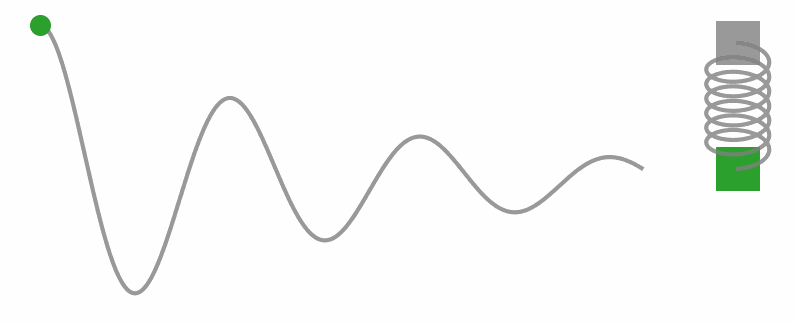

**The spring.** For small stretches, a spring pulls back in proportion to the displacement (Hooke's law):
$$
F_{\text{spring}} = -k\,x ,
$$
where $k>0$ is the stiffness. The minus sign says the force points opposite to the displacement.

**The damper.** We take the friction to be viscous, meaning it is proportional to speed and also opposes motion:
$$
F_{\text{damping}} = -c\,\dot x ,
\qquad \dot x \equiv \frac{dx}{dt},
$$
with $c>0$ the damping coefficient. (This is what a piston moving through oil does, and it is a good approximation for many shock absorbers at moderate speeds. Dry friction and fast air drag behave differently.)

**Newton's second law** says mass times acceleration equals the total force:
$$
m\,\ddot x = -k\,x - c\,\dot x
\quad\Longrightarrow\quad
\boxed{\,m\,\ddot x + c\,\dot x + k\,x = 0\,}
$$

This is a **linear, second-order, homogeneous ordinary differential equation** with constant coefficients. "Second-order" because the highest derivative is $\ddot x$. "Linear" because $x$ and its derivatives only appear to the first power, which is what makes it exactly solvable.


## 3. Two numbers that describe the behaviour

Divide through by $m$:
$$
\ddot x + \frac{c}{m}\,\dot x + \frac{k}{m}\,x = 0 .
$$
Two combinations of the physical constants control everything. Define
$$
\omega_0=\sqrt{\frac{k}{m}},
\qquad
\zeta=\frac{c}{2\sqrt{m k}} .
$$

* $\omega_0$ is the **natural angular frequency**: how fast the system would swing if there were no friction ($c=0$). Its unit is radians per second.
* $\zeta$ (zeta) is the **damping ratio**. It is dimensionless and compares the actual damping with the amount that would just stop the oscillation.

Using these, $c/m = 2\zeta\omega_0$ and $k/m=\omega_0^2$, so the equation takes its standard form
$$
\boxed{\,\ddot x + 2\zeta\omega_0\,\dot x + \omega_0^{2}\,x = 0\,}
\tag{1}
$$
We will use (1) for the exact solution and $m\ddot x + c\dot x + kx = 0$ inside the loss function, which is the same equation written two ways.

## 4. Solving it exactly

We want the exact solution for two reasons: to generate the test data, and to judge the neural network at the end, because a PINN has to be compared with the truth to know whether it worked.

### 4.1 Guess an exponential
Linear equations with constant coefficients are solved by exponentials, because differentiating $e^{rt}$ just multiplies it by $r$. Try $x(t)=e^{rt}$ in (1). Then $\dot x=r e^{rt}$ and $\ddot x=r^2 e^{rt}$, so
$$
\big(r^{2}+2\zeta\omega_0\, r+\omega_0^{2}\big)\,e^{rt}=0 .
$$
Since $e^{rt}$ is never zero, the bracket must be zero. This is the **characteristic equation**:
$$
r^{2}+2\zeta\omega_0\, r+\omega_0^{2}=0 .
$$

### 4.2 Solve the quadratic
By the quadratic formula,
$$
r_{1,2}=-\zeta\omega_0\;\pm\;\omega_0\sqrt{\zeta^{2}-1}.
$$
What kind of numbers these are depends on the sign of $\zeta^2-1$, which gives three different behaviours:

| Damping ratio | Roots | Name | What you see |
|---|---|---|---|
| $\zeta<1$ | complex pair | **underdamped** | oscillation with shrinking amplitude |
| $\zeta=1$ | one repeated real root | **critically damped** | fastest return to rest with no overshoot |
| $\zeta>1$ | two different real roots | **overdamped** | slow creep back to rest, no oscillation |

Our experiment uses the underdamped case. The other two are derived at the end of this section so the picture is complete.

### 4.3 The underdamped case in detail ($0<\zeta<1$)
Now $\zeta^2-1<0$, so the square root is imaginary. Write $\sqrt{\zeta^2-1}=i\sqrt{1-\zeta^2}$ and define

$$
\alpha=\zeta\omega_0 ,\qquad
\omega_d=\omega_0\sqrt{1-\zeta^{2}} .
$$

* $\alpha$ is the **decay rate**. The amplitude shrinks like $e^{-\alpha t}$.
* $\omega_d$ is the **damped angular frequency**. It is always a little lower than $\omega_0$: friction slows the swing slightly.

The roots are $r_{1,2}=-\alpha\pm i\,\omega_d$. The two exponential solutions are $e^{(-\alpha\pm i\omega_d)t}=e^{-\alpha t}\,e^{\pm i\omega_d t}$.

**Getting real solutions.** Euler's formula says $e^{i\theta}=\cos\theta+i\sin\theta$. Because the equation is linear, any combination of solutions is also a solution, so we can add and subtract the two to remove the $i$:
$$
\tfrac12\big(e^{i\omega_d t}+e^{-i\omega_d t}\big)=\cos\omega_d t,
\qquad
\tfrac1{2i}\big(e^{i\omega_d t}-e^{-i\omega_d t}\big)=\sin\omega_d t .
$$
So $e^{-\alpha t}\cos\omega_d t$ and $e^{-\alpha t}\sin\omega_d t$ are both real solutions, and the general solution is
$$
x(t)=e^{-\alpha t}\big(C_1\cos\omega_d t + C_2\sin\omega_d t\big).
\tag{2}
$$

**Using the initial conditions.** A second-order equation has two free constants, so we need two conditions. Take the starting position $x(0)=x_0$ and starting velocity $\dot x(0)=v_0$.

* At $t=0$: $\cos 0=1$ and $\sin 0=0$, so $x(0)=C_1$. Hence $C_1=x_0$.
* For the velocity, differentiate (2) with the product rule:
$$
\dot x(t)=e^{-\alpha t}\Big[(-\alpha C_1+\omega_d C_2)\cos\omega_d t-(\alpha C_2+\omega_d C_1)\sin\omega_d t\Big].
$$
At $t=0$ this is $\dot x(0)=-\alpha C_1+\omega_d C_2=v_0$, so $C_2=\dfrac{v_0+\alpha x_0}{\omega_d}$.

The complete solution for our problem is therefore
$$
\boxed{\,x(t)=e^{-\alpha t}\left[x_0\cos\omega_d t+\frac{v_0+\alpha x_0}{\omega_d}\,\sin\omega_d t\right]\,}
\tag{3}
$$

**Amplitude and phase form.** Any sum $C_1\cos\theta + C_2\sin\theta$ can be written as $A\cos(\theta-\varphi)$ with $A=\sqrt{C_1^2+C_2^2}$ and $\tan\varphi=C_2/C_1$. So
$$
x(t)=A\,e^{-\alpha t}\cos(\omega_d t-\varphi).
$$
The curves $\pm A e^{-\alpha t}$ form an **envelope**: the oscillation stays inside them and touches them at its peaks. This envelope is the "decreasing amplitude curve" you will see in the plots and the video.

**Two useful measurements.**

* *Damped period:* $T_d = 2\pi/\omega_d$.
* *Ratio of successive peaks.* One period later the cosine repeats but the envelope has shrunk by $e^{-\alpha T_d}$. Taking the natural log gives the **logarithmic decrement**
$$
\delta=\alpha T_d=\frac{2\pi\zeta}{\sqrt{1-\zeta^{2}}} .
$$
Engineers use this to estimate $\zeta$ from a recording: measure two successive peaks, take the log of their ratio, and solve for $\zeta$.

### 4.4 The other two regimes
**Critical damping ($\zeta=1$).** The discriminant is zero, so there is a single repeated root $r=-\omega_0$. Then $e^{-\omega_0 t}$ is one solution, and a second independent one is $t\,e^{-\omega_0 t}$. (Check: substituting $x=te^{rt}$ into the equation gives $(r^2+2\zeta\omega_0 r+\omega_0^2)\,t e^{rt}+(2r+2\zeta\omega_0)e^{rt}$. The first bracket is zero, and the second is zero when $r=-\zeta\omega_0$, which is exactly the repeated root.) The solution is
$$
x(t)=(C_1+C_2 t)\,e^{-\omega_0 t},\qquad C_1=x_0,\quad C_2=v_0+\omega_0 x_0 .
$$

**Overdamping ($\zeta>1$).** Both roots are real and negative: $r_{1,2}=-\omega_0\big(\zeta\mp\sqrt{\zeta^2-1}\big)$. The solution is $x=C_1e^{r_1 t}+C_2 e^{r_2 t}$. The conditions $C_1+C_2=x_0$ and $r_1C_1+r_2C_2=v_0$ give
$$
C_1=\frac{v_0-r_2x_0}{r_1-r_2},\qquad C_2=\frac{r_1x_0-v_0}{r_1-r_2}.
$$
(Adding $C_1+C_2$ gives $x_0$ and $r_1C_1+r_2C_2$ gives $v_0$, which you can confirm in one line.)

### 4.5 Why two initial conditions?
A second-order equation can be rewritten as two first-order ones. Let $y_1=x$ and $y_2=\dot x$. Then
$$
\dot y_1=y_2,\qquad \dot y_2=-2\zeta\omega_0\,y_2-\omega_0^{2}\,y_1 .
$$
The state of the system is the pair $(y_1,y_2)$ = (position, velocity). To know where the system goes next, you need both numbers at the start. Think of two identical weights released from the same spot, one dropped and one flicked upwards: same position at $t=0$, completely different futures. In the ball example, one initial condition was enough because the equation was first-order and had a single state variable.

### 4.6 Energy always drains
The mechanical energy is the kinetic part plus the spring part:
$$
E(t)=\tfrac12\,m\,\dot x^{2}+\tfrac12\,k\,x^{2}.
$$
Differentiate in time and use the equation of motion:
$$
\frac{dE}{dt}=m\dot x\ddot x+kx\dot x=\dot x\,\big(m\ddot x+kx\big)=\dot x\,(-c\dot x)=-c\,\dot x^{2}\;\le 0 .
$$
So the energy never increases, and it decreases whenever the weight is moving. This gives us a physical sanity check that does not need the exact solution: **if a model of the motion ever shows $E$ going up, it is breaking the physics.** We will test this on the networks in both parts.


## 5. The numbers used in this notebook

We pick $m=1$ kg, $k=16$ N/m, $c=0.8$ N·s/m, and release the weight from $x_0=1$ m with zero velocity ($v_0=0$). Then

| Quantity | Value |
|---|---|
| $\omega_0=\sqrt{k/m}$ | $4$ rad/s |
| $\zeta=c/(2\sqrt{mk})$ | $0.1$ (lightly damped) |
| decay rate $\alpha=\zeta\omega_0$ | $0.4$ per second |
| $\omega_d=\omega_0\sqrt{1-\zeta^2}$ | $3.980$ rad/s |
| damped period $T_d=2\pi/\omega_d$ | $1.579$ s |
| amplitude left after one period, $e^{-\alpha T_d}$ | about $0.53$ |

We model $t\in[0,4]$ seconds, which is roughly two and a half swings, and the amplitude falls to about 20% of its starting value by the end.

## 6. What goes wrong with a network trained on data alone

Now the experiment. Suppose we only manage to record the **first 1.8 seconds**, about one and a bit swings, and the readings are noisy. We train a network $\hat x_\theta(t)$ with the usual mean squared error on those points.

Inside the recorded window it does fine. Outside it, nothing ties it down. A network is a flexible curve, and the data never said anything about $t>1.8$, so the curve it draws there depends on the random starting weights and the training path. It might flatten out, wander, or (as we will see) shoot off to a large value. It does not know that the weight is supposed to keep swinging with shrinking amplitude.

This is the plainest argument for adding physics: we are not just smoothing out noise (as in the ball example), we are asking the network to **extrapolate**, and equations are what let us do that.

## 7. The PINN loss for a second-order equation

The network takes $t$ and returns $\hat x(t)$. Because the network is built from smooth functions, we can differentiate it with respect to $t$, once for the velocity $\hat x'(t)$ and twice for the acceleration $\hat x''(t)$. Four loss terms follow.

**Data loss.** Mean squared error against the $N_d$ noisy readings $(t_i,x_i)$:
$$
\mathcal L_{\text{data}}=\frac1{N_d}\sum_{i=1}^{N_d}\big(\hat x(t_i)-x_i\big)^2 .
$$

**Physics (ODE) loss.** Take $N_p$ times $\tau_j$ spread over the whole interval $[0,4]$, including times with no measurement. At each one, plug the network into the equation and see how far from zero it is. The leftover is called the **residual**:
$$
r(\tau_j)=\frac{m\,\hat x''(\tau_j)+c\,\hat x'(\tau_j)+k\,\hat x(\tau_j)}{k},
\qquad
\mathcal L_{\text{ODE}}=\frac1{N_p}\sum_{j=1}^{N_p} r(\tau_j)^2 .
$$
The times $\tau_j$ are often called **collocation points**. They cost nothing, because evaluating the equation needs no measurement.

*Why divide by $k$?* Without it, the first term would be about $m\ddot x\approx\omega_0^2=16$ times larger than the displacement itself, and the loss would be about 256 times larger than a data error of the same relative size. The physics would drown out the data. Dividing by $k$ puts the residual on the same scale as a position, so the loss weights stay close to 1. This rescaling is a choice we make, not part of the physics.

**Initial-condition losses.** Two conditions, so two terms:
$$
\mathcal L_{\text{IC}}=\big(\hat x(0)-x_0\big)^2+\left(\frac{\hat x'(0)-v_0}{\omega_0}\right)^{2}.
$$
The velocity error is divided by $\omega_0$ so that it is measured in position units, for the same reason as above.

**Total loss.**
$$
\mathcal L(\theta)=\lambda_{\text{data}}\,\mathcal L_{\text{data}}+\lambda_{\text{ODE}}\,\mathcal L_{\text{ODE}}+\lambda_{\text{IC}}\,\mathcal L_{\text{IC}} .
$$
Setting $\lambda_{\text{ODE}}=\lambda_{\text{IC}}=0$ gives the plain data-only network that we compare against.

## 8. Differentiating the network twice

The network has three hidden layers with $\tanh$ activations. Write the input as $t$ and the layer-by-layer values as
$$
\mathbf z_\ell=\mathbf a_{\ell-1}\mathbf W_\ell+\mathbf b_\ell,\qquad
\mathbf a_\ell=\tanh(\mathbf z_\ell),\qquad \mathbf a_0=t,
$$
with a linear last layer $\hat x=\mathbf a_L\mathbf W_{L+1}+\mathbf b_{L+1}$.

To get $\hat x'$ and $\hat x''$ we carry three quantities forward through the layers: the value, its first time derivative, and its second time derivative. Use a dot for $d/dt$.

* **Linear step.** The weights do not depend on $t$, so derivatives pass straight through the matrix multiplication:
$$
\mathbf z=\mathbf a\mathbf W+\mathbf b,\qquad
\dot{\mathbf z}=\dot{\mathbf a}\mathbf W,\qquad
\ddot{\mathbf z}=\ddot{\mathbf a}\mathbf W .
$$
* **Activation step.** With $\mathbf a=\tanh \mathbf z$ and $\mathbf s=1-\mathbf a^2$ (this is $\tanh'$), the chain rule gives
$$
\dot{\mathbf a}=\mathbf s\odot\dot{\mathbf z}.
$$
Differentiating once more with the product rule, and using $\dot{\mathbf s}=-2\mathbf a\odot\dot{\mathbf a}=-2\mathbf a\odot\mathbf s\odot\dot{\mathbf z}$:
$$
\ddot{\mathbf a}=\dot{\mathbf s}\odot\dot{\mathbf z}+\mathbf s\odot\ddot{\mathbf z}
=\mathbf s\odot\ddot{\mathbf z}-2\,\mathbf a\odot\mathbf s\odot\dot{\mathbf z}^{\,2}.
$$
* **Start of the chain.** The input is $t$ itself, so $\dot{\mathbf a}_0=1$ and $\ddot{\mathbf a}_0=0$.

Run these through every layer and the last linear layer outputs $\hat x$, $\hat x'$ and $\hat x''$ together. This is what Part A codes by hand. In Part B, PyTorch does the same job for us by applying automatic differentiation twice.

## 9. Training: Adam with a decaying step size

We minimise $\mathcal L(\theta)$ with Adam (explained in Part A). The oscillator needs more epochs than the ball did, and a fixed learning rate tends to jitter near the end. So we start with a larger step and let it shrink smoothly, geometrically, from $\eta_0$ to $\eta_1$ over $K$ epochs:
$$
\eta_k=\eta_0\left(\frac{\eta_1}{\eta_0}\right)^{k/K}.
$$
We use $\eta_0=3\times10^{-3}$, $\eta_1=10^{-4}$ and $K=20{,}000$ epochs.

## 10. Why oscillations are harder than the ball

A few honest warnings, because PINNs are easy to oversell:

* **Fast wiggles are slow to learn.** Networks tend to pick up smooth, slowly changing shapes first and fine detail later. A parabola is smooth. Two and a half swings are not. That is why we need thousands of epochs, and why you will see the video start with a gentle curve and gradually grow the oscillation.
* **Long time spans get harder.** The longer the interval relative to the oscillation period, the harder it is for the physics term to hold the whole curve together. Researchers have documented this kind of failure on simple equations (Krishnapriyan et al., 2021; Wang et al., 2022, see References).
* **The loss terms compete.** The data, ODE and initial-condition gradients can pull in different directions with different strengths (Wang et al., 2021). The rescaling in section 7 is a simple first step. More careful weighting schemes exist.
* **It is slower than a classical solver.** For an ODE this simple, a standard numerical integrator is faster and more accurate. A PINN earns its place when data and equations have to be combined, when parts of the physics are unknown, or when the problem is a PDE with awkward geometry.

## 11. The inverse problem: finding the friction from data

So far we assumed the damping coefficient $c$ is known. In practice it often is not. A shock absorber wears out, or a sensor beam has an unknown amount of air damping. The PINN setup handles this with a small change: make $c$ one more trainable number, and let the same loss that fits the data also adjust $c$ until the equation agrees with the measurements.
$$
\min_{\theta,\,c}\;\mathcal L(\theta,c) .
$$
The extra gradient we need is easy: from section 7 the residual depends on $c$ through $c\,\hat x'/k$, so
$$
\frac{\partial\mathcal L_{\text{ODE}}}{\partial c}=\frac1{N_p}\sum_j 2\,r(\tau_j)\,\frac{\hat x'(\tau_j)}{k}.
$$
The same idea was used in the original PINN paper by Raissi and co-workers to learn unknown constants in equations from data. We do this in A12 (NumPy) and B9 (PyTorch).

---
# Setup (shared by both parts)

The cells in this section define the physical constants, the exact solution, the measurements, and the helper functions for plotting and for making the training video. Only NumPy and Matplotlib are used. Run them once, then go to Part A or Part B.

## S1. Imports

In [1]:
import os
import time
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

# a folder for the video and the GIF
MEDIA_DIR = Path("media")
MEDIA_DIR.mkdir(exist_ok=True)

## S2. Physical constants
The values come from section 5 of the background. We also compute $\omega_0$, $\zeta$, $\alpha$ and $\omega_d$ so every later formula can reuse them.

In [2]:
# physical parameters of the mass-spring-damper
m = 1.0        # mass (kg)
k = 16.0       # spring stiffness (N/m)
c = 0.8        # damping coefficient (N s/m)
x0 = 1.0       # initial position (m)
v0 = 0.0       # initial velocity (m/s)

# derived quantities
omega0 = np.sqrt(k / m)                     # natural angular frequency
zeta = c / (2.0 * np.sqrt(m * k))           # damping ratio
alpha = zeta * omega0                       # decay rate
omega_d = omega0 * np.sqrt(1.0 - zeta**2)   # damped angular frequency
T_d = 2.0 * np.pi / omega_d                 # damped period

print(f"omega0 = {omega0:.3f} rad/s")
print(f"zeta   = {zeta:.3f}  (underdamped, since zeta < 1)")
print(f"alpha  = {alpha:.3f} 1/s")
print(f"omega_d = {omega_d:.4f} rad/s")
print(f"damped period = {T_d:.3f} s")

omega0 = 4.000 rad/s
zeta   = 0.100  (underdamped, since zeta < 1)
alpha  = 0.400 1/s
omega_d = 3.9799 rad/s
damped period = 1.579 s


## S3. The exact solution, for all three damping regimes
The function below implements the solutions derived in sections 4.3 and 4.4: underdamped (formula 3), critically damped and overdamped. We use it to create the test data and to judge the networks. The values of $m$, $k$, $c$ are given through $\omega_0$ and $\zeta$.

In [3]:
def oscillator_solution(t, omega0, zeta, x0, v0):
    # exact solution of x'' + 2*zeta*omega0*x' + omega0^2*x = 0 with x(0)=x0, x'(0)=v0
    t = np.asarray(t, dtype=float)
    if zeta < 1.0 - 1e-9:                       # underdamped
        a = zeta * omega0
        wd = omega0 * np.sqrt(1.0 - zeta**2)
        return np.exp(-a * t) * (x0 * np.cos(wd * t) + (v0 + a * x0) / wd * np.sin(wd * t))
    if abs(zeta - 1.0) <= 1e-9:                 # critically damped
        return (x0 + (v0 + omega0 * x0) * t) * np.exp(-omega0 * t)
    root = omega0 * np.sqrt(zeta**2 - 1.0)      # overdamped
    r1, r2 = -zeta * omega0 + root, -zeta * omega0 - root
    C1 = (v0 - r2 * x0) / (r1 - r2)
    C2 = (r1 * x0 - v0) / (r1 - r2)
    return C1 * np.exp(r1 * t) + C2 * np.exp(r2 * t)


def true_solution(t):
    # the solution for the constants chosen above
    return oscillator_solution(t, omega0, zeta, x0, v0)


def true_energy(t, h=1e-4):
    # mechanical energy of the exact solution (velocity by central difference)
    t = np.asarray(t, dtype=float)
    v = (true_solution(t + h) - true_solution(t - h)) / (2 * h)
    return 0.5 * m * v**2 + 0.5 * k * true_solution(t)**2

**A quick check of the algebra.** If formula (3) is right, it must satisfy $m\ddot x+c\dot x+kx=0$ at every time. We estimate the derivatives numerically with central differences (step $h$) and look at how close the left side is to zero. A small number here is a good sign that the derivation in section 4 has no mistakes.

In [4]:
t_test = np.linspace(0.1, 3.9, 200)
h = 1e-4
x_t = true_solution(t_test)
x_dot = (true_solution(t_test + h) - true_solution(t_test - h)) / (2 * h)
x_ddot = (true_solution(t_test + h) - 2 * x_t + true_solution(t_test - h)) / h**2

residual = m * x_ddot + c * x_dot + k * x_t
print(f"largest |m x'' + c x' + k x| over the grid: {np.max(np.abs(residual)):.2e}")
print(f"x(0) = {true_solution(0.0):.6f} (should be {x0})")
print(f"x'(0) = {(true_solution(h) - true_solution(-h)) / (2 * h):.6f} (should be {v0})")

largest |m x'' + c x' + k x| over the grid: 2.13e-07
x(0) = 1.000000 (should be 1.0)
x'(0) = 0.000000 (should be 0.0)


## S4. The three damping regimes
Same $\omega_0$, same starting position, three different amounts of friction. The dashed lines in the underdamped panel are the envelope $\pm A e^{-\alpha t}$ from section 4.3.

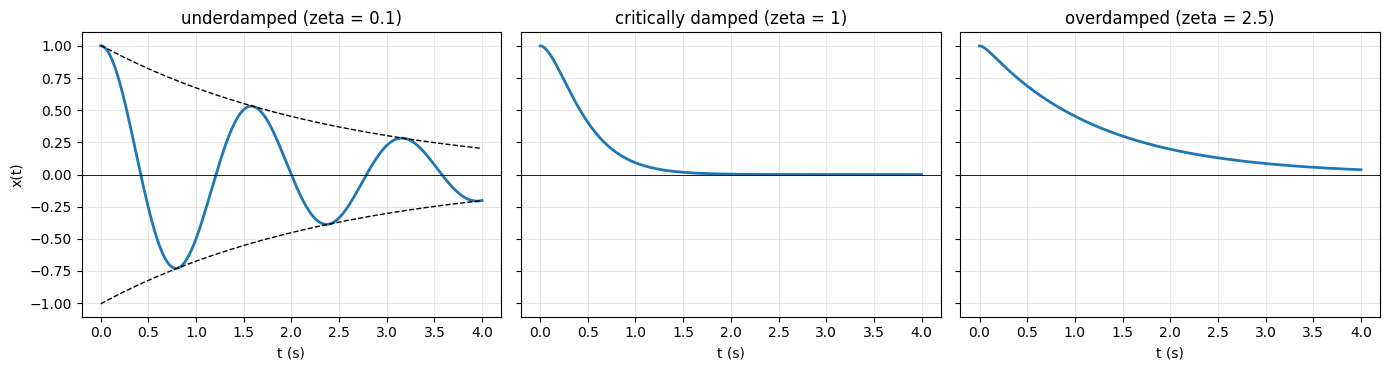

In [5]:
t_show = np.linspace(0, 4, 600)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, z, name in zip(axes, [0.1, 1.0, 2.5], ["underdamped (zeta = 0.1)", "critically damped (zeta = 1)", "overdamped (zeta = 2.5)"]):
    ax.plot(t_show, oscillator_solution(t_show, omega0, z, x0, v0), lw=2)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(name)
    ax.set_xlabel("t (s)")
    ax.grid(alpha=0.3)
    if z < 1:
        wd = omega0 * np.sqrt(1 - z**2)
        A = np.sqrt(x0**2 + ((v0 + z * omega0 * x0) / wd)**2)
        ax.plot(t_show, A * np.exp(-z * omega0 * t_show), "k--", lw=1)
        ax.plot(t_show, -A * np.exp(-z * omega0 * t_show), "k--", lw=1)
axes[0].set_ylabel("x(t)")
plt.tight_layout()
plt.show()

**Try it yourself (Jupyter or Colab).** The next cell makes sliders for the damping ratio, the natural frequency and the starting conditions. Drag $\zeta$ across 1 and watch the oscillation disappear. If `ipywidgets` is not installed, the cell prints a hint and moves on. It does not affect the rest of the notebook.

In [6]:
def explore_oscillator(zeta_value=0.1, omega0_value=4.0, x0_value=1.0, v0_value=0.0):
    tt = np.linspace(0, 6, 800)
    xx = oscillator_solution(tt, omega0_value, zeta_value, x0_value, v0_value)
    plt.figure(figsize=(8, 3.8))
    plt.plot(tt, xx, lw=2)
    plt.axhline(0, color="k", lw=0.6)
    if zeta_value < 1:
        regime = "underdamped"
    elif abs(zeta_value - 1) < 1e-9:
        regime = "critically damped"
    else:
        regime = "overdamped"
    plt.title(f"{regime}: zeta = {zeta_value:.2f}, omega0 = {omega0_value:.1f} rad/s")
    plt.xlabel("t (s)")
    plt.ylabel("x(t)")
    plt.ylim(-2.2, 2.2)
    plt.grid(alpha=0.3)
    plt.show()

try:
    import ipywidgets as widgets
    widgets.interact(
        explore_oscillator,
        zeta_value=widgets.FloatSlider(value=0.1, min=0.02, max=2.5, step=0.02, description="zeta"),
        omega0_value=widgets.FloatSlider(value=4.0, min=1.0, max=10.0, step=0.5, description="omega0"),
        x0_value=widgets.FloatSlider(value=1.0, min=-2.0, max=2.0, step=0.1, description="x0"),
        v0_value=widgets.FloatSlider(value=0.0, min=-10.0, max=10.0, step=0.5, description="v0"),
    )
except ImportError:
    print("ipywidgets is not installed. Run: pip install ipywidgets")

interactive(children=(FloatSlider(value=0.1, description='zeta', max=2.5, min=0.02, step=0.02), FloatSlider(va…

## S5. The measurements
We observe the weight only during the **first 1.8 seconds** with 18 evenly spaced readings, each with Gaussian noise of standard deviation 0.05 m (5% of the starting displacement). The physics will be checked at 120 evenly spaced times over the **full** 4 seconds. The random seed is fixed so every run gives the same data.

In [7]:
# time domain and observation window
t_min, t_max = 0.0, 4.0
t_obs_end = 1.8             # we only measure up to this time
N_data = 18
N_phys = 120                # collocation points for the physics loss

# noisy measurements (column vectors, one row per reading)
np.random.seed(0)
noise_level = 0.05
t_obs = np.linspace(t_min, t_obs_end, N_data).reshape(-1, 1)
x_obs = true_solution(t_obs) + noise_level * np.random.randn(N_data, 1)

# times where the physics will be checked
t_phys = np.linspace(t_min, t_max, N_phys).reshape(-1, 1)

# fine grid for plotting and error measurement
t_grid = np.linspace(t_min, t_max, 400).reshape(-1, 1)
x_exact_grid = true_solution(t_grid)

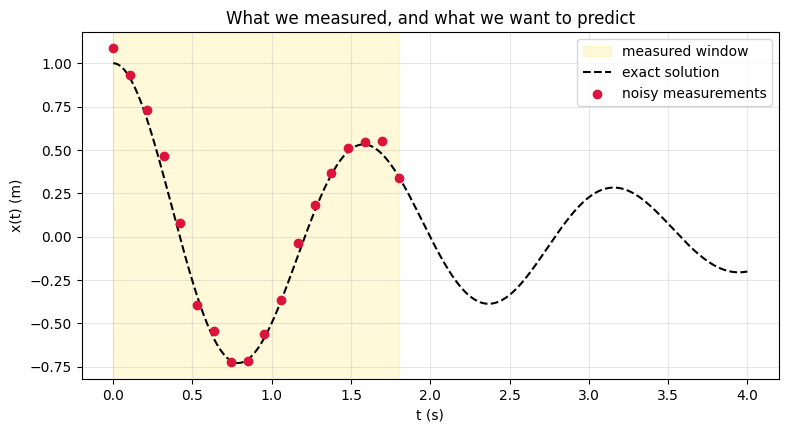

In [8]:
plt.figure(figsize=(9, 4.5))
plt.axvspan(t_min, t_obs_end, color="gold", alpha=0.15, label="measured window")
plt.plot(t_grid, x_exact_grid, "k--", label="exact solution")
plt.scatter(t_obs, x_obs, color="crimson", zorder=3, label="noisy measurements")
plt.xlabel("t (s)")
plt.ylabel("x(t) (m)")
plt.title("What we measured, and what we want to predict")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## S6. Helper functions: error measures, training snapshots and the video

These are used by both parts, so they live here.

* `rmse` and `window_errors` measure how far a prediction is from the exact curve, inside the measured window and outside it.
* `make_snapshot_epochs` chooses which epochs to record during training. They are spaced geometrically (many early on, fewer later), because most visible change happens in the first few hundred epochs.
* `make_training_video` draws the two-panel animation and saves it as an MP4, a GIF, or both.
* `convert_mp4_to_gif` turns an existing MP4 into a GIF using `ffmpeg` (with a colour palette for better quality).
* `scrub_epochs` makes a slider so you can move through training by hand.

In [9]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def window_errors(pred_on_grid):
    # RMSE against the exact solution: inside the measured window, outside it, and overall
    pred = np.asarray(pred_on_grid).reshape(-1, 1)
    inside = (t_grid <= t_obs_end)
    return {
        "inside window": rmse(pred[inside], x_exact_grid[inside]),
        "outside window": rmse(pred[~inside], x_exact_grid[~inside]),
        "overall": rmse(pred, x_exact_grid),
    }


def make_snapshot_epochs(epochs, n_snapshots=90):
    # epoch 0 (before training) plus a geometric spread up to the final epoch
    spread = np.unique(np.round(np.geomspace(1, epochs, n_snapshots)).astype(int))
    return sorted(set([0] + spread.tolist()))

In [10]:
def find_ffmpeg():
    # look for ffmpeg on the PATH, then in the imageio-ffmpeg package if it is installed
    path = shutil.which("ffmpeg")
    if path:
        return path
    try:
        import imageio_ffmpeg
        return imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        return None


def make_training_video(epochs_saved, preds_a, preds_b,
                        name_a="Data only (no physics)", name_b="Data + physics (PINN)",
                        mp4_path=None, gif_path=None, fps=12, hold_frames=18,
                        mp4_dpi=90, gif_dpi=60):

    # Two panels side by side showing how two networks fit the curve as training goes on,
    # and a lower panel with the error against the exact solution.
    #   epochs_saved : list of epoch numbers
    #   preds_a/b    : arrays of shape (n_snapshots, n_grid) with each network's prediction

    epochs_saved = np.asarray(epochs_saved)
    preds_a = np.asarray(preds_a).reshape(len(epochs_saved), -1)
    preds_b = np.asarray(preds_b).reshape(len(epochs_saved), -1)
    exact = x_exact_grid.ravel()
    tg = t_grid.ravel()
    err_a = np.sqrt(np.mean((preds_a - exact) ** 2, axis=1))
    err_b = np.sqrt(np.mean((preds_b - exact) ** 2, axis=1))
    epochs_plot = np.maximum(epochs_saved, 1)       # epoch 0 would break a log axis

    fig = plt.figure(figsize=(12, 6.4))             # 12 x 6.4 inches: even pixel sizes for MP4
    gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1])
    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1], sharey=ax_a)
    ax_e = fig.add_subplot(gs[1, :])

    for ax, name in ((ax_a, name_a), (ax_b, name_b)):
        ax.axvspan(t_min, t_obs_end, color="gold", alpha=0.15, label="measured window")
        ax.plot(tg, exact, "k--", lw=1.2, label="exact solution")
        ax.scatter(t_obs, x_obs, s=16, color="crimson", zorder=3, label="noisy data")
        ax.set_title(name, fontsize=12)
        ax.set_xlabel("t (s)")
        ax.set_ylim(-1.45, 1.45)
        ax.grid(alpha=0.3)
    ax_a.set_ylabel("x(t)")
    ax_b.plot(t_phys.ravel(), np.full(t_phys.size, -1.36), "|", color="seagreen", alpha=0.6,
              markersize=7, label="physics checked here")
    note_a = ax_a.text(0.98, 0.05, "", transform=ax_a.transAxes, ha="right", fontsize=9, color="tab:orange")
    note_b = ax_b.text(0.98, 0.05, "", transform=ax_b.transAxes, ha="right", fontsize=9, color="tab:blue")
    line_a, = ax_a.plot([], [], color="tab:orange", lw=2.4, label="network")
    line_b, = ax_b.plot([], [], color="tab:blue", lw=2.4, label="network")
    ax_a.legend(loc="upper right", fontsize=8)
    ax_b.legend(loc="upper right", fontsize=8)

    ax_e.set_xscale("log")
    ax_e.set_yscale("log")
    ax_e.set_xlim(1, epochs_saved.max() * 1.1)
    lo = min(err_a.min(), err_b.min()) * 0.7
    hi = max(err_a.max(), err_b.max()) * 1.4
    ax_e.set_ylim(lo, hi)
    ax_e.set_xlabel("epoch")
    ax_e.set_ylabel("RMSE vs exact (m)")
    ax_e.grid(alpha=0.3, which="both")
    curve_a, = ax_e.plot([], [], color="tab:orange", lw=2, label=name_a)
    curve_b, = ax_e.plot([], [], color="tab:blue", lw=2, label=name_b)
    dot_a, = ax_e.plot([], [], "o", color="tab:orange")
    dot_b, = ax_e.plot([], [], "o", color="tab:blue")
    ax_e.legend(loc="lower left", fontsize=8)
    title = fig.suptitle("", fontsize=15, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95))

    frames = list(range(len(epochs_saved))) + [len(epochs_saved) - 1] * hold_frames

    def update(i):
        line_a.set_data(tg, preds_a[i])
        line_b.set_data(tg, preds_b[i])
        curve_a.set_data(epochs_plot[: i + 1], err_a[: i + 1])
        curve_b.set_data(epochs_plot[: i + 1], err_b[: i + 1])
        dot_a.set_data([epochs_plot[i]], [err_a[i]])
        dot_b.set_data([epochs_plot[i]], [err_b[i]])
        title.set_text(f"Training epoch {int(epochs_saved[i]):,}")
        off_a = np.abs(preds_a[i]).max() > 1.45          # the curve left the plotting frame
        off_b = np.abs(preds_b[i]).max() > 1.45
        note_a.set_text("(curve leaves the frame)" if off_a else "")
        note_b.set_text("(curve leaves the frame)" if off_b else "")
        return line_a, line_b, curve_a, curve_b, dot_a, dot_b, title, note_a, note_b

    anim = animation.FuncAnimation(fig, update, frames=frames, interval=1000 / fps, blit=False)

    if gif_path is not None:
        anim.save(str(gif_path), writer=animation.PillowWriter(fps=fps), dpi=gif_dpi)
        print(f"saved GIF: {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    if mp4_path is not None:
        ffmpeg = find_ffmpeg()
        if ffmpeg is None:
            print("ffmpeg was not found, so no MP4 was written. "
                  "Install ffmpeg, or run: pip install imageio-ffmpeg")
        else:
            plt.rcParams["animation.ffmpeg_path"] = ffmpeg
            anim.save(str(mp4_path), writer=animation.FFMpegWriter(fps=fps, bitrate=2000), dpi=mp4_dpi)
            print(f"saved MP4: {mp4_path}  ({Path(mp4_path).stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)
    return anim


def convert_mp4_to_gif(mp4_path, gif_path, fps=12, width=800):
    # Convert an existing MP4 into a GIF with ffmpeg. The palette step keeps the colours clean.
    ffmpeg = find_ffmpeg()
    if ffmpeg is None:
        print("ffmpeg was not found, so the MP4 could not be converted.")
        return None
    filters = (f"fps={fps},scale={width}:-1:flags=lanczos,"
               "split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse")
    subprocess.run([ffmpeg, "-y", "-loglevel", "error", "-i", str(mp4_path),
                    "-vf", filters, str(gif_path)], check=True)
    print(f"converted {mp4_path} -> {gif_path}  ({Path(gif_path).stat().st_size / 1e6:.1f} MB)")
    return gif_path

In [11]:
def scrub_epochs(epochs_saved, preds_a, preds_b,
                 name_a="Data only (no physics)", name_b="Data + physics (PINN)"):
    # An epoch slider: drag to move through training (needs ipywidgets in Jupyter or Colab).
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets is not installed. Run: pip install ipywidgets")
        return
    preds_a = np.asarray(preds_a).reshape(len(epochs_saved), -1)
    preds_b = np.asarray(preds_b).reshape(len(epochs_saved), -1)

    def draw(snapshot):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
        for ax, preds, name, colour in ((axes[0], preds_a, name_a, "tab:orange"),
                                        (axes[1], preds_b, name_b, "tab:blue")):
            ax.axvspan(t_min, t_obs_end, color="gold", alpha=0.15)
            ax.plot(t_grid, x_exact_grid, "k--", lw=1.2, label="exact")
            ax.scatter(t_obs, x_obs, s=16, color="crimson", zorder=3, label="data")
            ax.plot(t_grid, preds[snapshot], color=colour, lw=2.4, label="network")
            ax.set_title(f"{name}\nRMSE = {rmse(preds[snapshot], x_exact_grid):.3f} m")
            ax.set_xlabel("t (s)")
            ax.set_ylim(-1.45, 1.45)
            ax.grid(alpha=0.3)
        axes[0].set_ylabel("x(t)")
        axes[0].legend(loc="upper right", fontsize=8)
        fig.suptitle(f"epoch {int(epochs_saved[snapshot]):,}", fontweight="bold")
        plt.tight_layout()
        plt.show()

    slider = widgets.SelectionSlider(
        options=[(f"{int(e):,}", i) for i, e in enumerate(epochs_saved)],
        description="epoch", layout=widgets.Layout(width="85%"))
    widgets.interact(draw, snapshot=slider)


def snapshot_grid(epochs_saved, preds_a, preds_b, picks=(0, 100, 1000, 5000, 20000),
                  name_a="Data only", name_b="Data + physics (PINN)"):
    # A still picture of a few moments in training (it also shows on GitHub, where sliders do not)
    epochs_saved = np.asarray(epochs_saved)
    preds_a = np.asarray(preds_a).reshape(len(epochs_saved), -1)
    preds_b = np.asarray(preds_b).reshape(len(epochs_saved), -1)
    idx = [int(np.argmin(np.abs(epochs_saved - p))) for p in picks]
    fig, axes = plt.subplots(2, len(idx), figsize=(3.2 * len(idx), 5.4), sharex=True, sharey=True)
    for col, i in enumerate(idx):
        for row, (preds, colour) in enumerate(((preds_a, "tab:orange"), (preds_b, "tab:blue"))):
            ax = axes[row, col]
            ax.axvspan(t_min, t_obs_end, color="gold", alpha=0.15)
            ax.plot(t_grid, x_exact_grid, "k--", lw=1)
            ax.scatter(t_obs, x_obs, s=8, color="crimson", zorder=3)
            ax.plot(t_grid, preds[i], color=colour, lw=2)
            ax.set_ylim(-1.45, 1.45)
            ax.grid(alpha=0.3)
            if row == 0:
                ax.set_title(f"epoch {int(epochs_saved[i]):,}", fontsize=11)
            if col == 0:
                ax.set_ylabel((name_a if row == 0 else name_b) + "\nx(t)")
            if row == 1:
                ax.set_xlabel("t (s)")
    plt.tight_layout()
    plt.show()

---
---
# Part A: From scratch with NumPy

Here the only tools are NumPy (arrays and matrix products) and Matplotlib. No machine-learning library, no automatic differentiation. We write:

1. a network whose forward pass returns the value, the first time derivative and the second time derivative,
2. the loss with its four terms,
3. the gradients of the loss by hand (and test them),
4. the Adam optimiser,
5. a training loop that also records snapshots for the video.

The point is to see exactly what a PINN does, so the later PyTorch version is not a black box.

## A1. The network and its forward pass with derivatives

The network is 1 → 32 → 32 → 32 → 1 with $\tanh$ in the hidden layers. Weights are stored in a dictionary: `W0, b0, W1, b1, ...`.

**Initial weights.** We use the Xavier (Glorot) uniform rule: each weight in a layer with $n_\text{in}$ inputs and $n_\text{out}$ outputs is drawn uniformly from $[-a,a]$ with $a=\sqrt{6/(n_\text{in}+n_\text{out})}$. It keeps the size of the signal roughly steady from layer to layer (Glorot and Bengio, 2010). Biases start at zero.

**The forward pass.** For each hidden layer we compute the value $\mathbf a$, and alongside it the first derivative $\dot{\mathbf a}$ and second derivative $\ddot{\mathbf a}$ with respect to time, exactly as derived in background section 8. In the code, `P, P1, P2` hold the value, first and second derivative arriving at a layer; `Z, Z1, Z2` are the same after the matrix product; `A, A1, A2` come out after $\tanh$; and `S` is $1-\mathbf a^2$. The arrays that the backward pass will need are stored in a list called `caches`.

In [12]:
def init_params(sizes, seed=0):
    # Xavier-uniform weights, zero biases. sizes = (1, 32, 32, 32, 1) for example.
    rng = np.random.default_rng(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        limit = np.sqrt(6.0 / (n_in + n_out))
        params[f"W{i}"] = rng.uniform(-limit, limit, size=(n_in, n_out))
        params[f"b{i}"] = np.zeros((1, n_out))
    return params


def n_layers(params):
    return sum(1 for key in params if key.startswith("W"))


def forward_jets(params, t):
    # returns x(t), x'(t), x''(t) for a batch of times t with shape (N, 1),
    # plus the stored arrays that backprop needs.
    L = n_layers(params)
    P, P1, P2 = t, np.ones_like(t), np.zeros_like(t)      # input: a0 = t, a0' = 1, a0'' = 0
    caches = []
    for l in range(L - 1):                                # hidden layers
        W, b = params[f"W{l}"], params[f"b{l}"]
        Z = P @ W + b                                     # linear step: value
        Z1 = P1 @ W                                       # first derivative
        Z2 = P2 @ W                                       # second derivative
        A = np.tanh(Z)                                    # activation
        S = 1.0 - A**2                                    # tanh'(Z)
        A1 = S * Z1
        A2 = S * Z2 - 2.0 * A * S * Z1**2
        caches.append((P, P1, P2, Z1, Z2, A, S))
        P, P1, P2 = A, A1, A2
    W, b = params[f"W{L-1}"], params[f"b{L-1}"]           # last layer is linear
    X = P @ W + b
    X1 = P1 @ W
    X2 = P2 @ W
    caches.append((P, P1, P2))
    return X, X1, X2, caches

## A2. The loss

Four pieces, as in background section 7. All the points are stacked into one batch so that a single forward pass handles them: the data times, then the collocation times, then $t=0$ for the initial conditions. The helper `make_batch` does the stacking and remembers where each group sits.

The ODE residual uses the physical constants `m`, `c`, `k` from the Setup section, and the damping coefficient is passed in as `c_val` so we can later let it change in the inverse problem.

In [13]:
def make_batch(t_data, x_data, t_ode):
    # stack data times, physics times and t = 0 into one array
    t_all = np.vstack([t_data, t_ode, np.zeros((1, 1))])
    return {"t": t_all, "x_data": x_data, "n_data": len(t_data), "n_ode": len(t_ode)}


def loss_terms(params, batch, c_val):
    # the four loss terms (data, ODE, IC position, IC velocity) without weights
    nd, no = batch["n_data"], batch["n_ode"]
    X, X1, X2, _ = forward_jets(params, batch["t"])
    r_data = X[:nd] - batch["x_data"]
    x_o, x1_o, x2_o = X[nd:nd + no], X1[nd:nd + no], X2[nd:nd + no]
    r_ode = (m * x2_o + c_val * x1_o + k * x_o) / k       # residual, scaled by k
    r_pos = X[-1:] - x0                                   # x(0) - x0
    r_vel = (X1[-1:] - v0) / omega0                       # (x'(0) - v0) / omega0
    return (np.mean(r_data**2), np.mean(r_ode**2), np.mean(r_pos**2), np.mean(r_vel**2))


def total_loss(params, batch, lam, c_val):
    l_data, l_ode, l_pos, l_vel = loss_terms(params, batch, c_val)
    lam_data, lam_ode, lam_ic = lam
    return lam_data * l_data + lam_ode * l_ode + lam_ic * (l_pos + l_vel)

## A3. Gradients by hand

To train, we need $\partial\mathcal L/\partial\theta$ for every weight and bias. This is backpropagation, but with a twist: because the loss contains $\hat x'$ and $\hat x''$, which are themselves computed from the weights, we have to push gradients back through the derivative formulas of section 8 too.

**Step 1: gradients at the output.** Differentiate each loss term with respect to the three network outputs $\hat x$, $\hat x'$, $\hat x''$ (call these gradients $g_X$, $g_{X1}$, $g_{X2}$). With $\mathcal L_{\text{data}}=\frac1{N_d}\sum r_i^2$ and similar for the others, the rule is $\partial(\text{mean of }r^2)/\partial r=2r/N$, and then the chain rule through the residual definitions:

* data: $g_X \mathrel{+}= \lambda_{\text{data}}\,\dfrac{2}{N_d}\,(\hat x-x_i)$
* ODE, with $r=(m\hat x''+c\hat x'+k\hat x)/k$: $\quad g_X \mathrel{+}= \lambda_{\text{ODE}}\dfrac{2r}{N_p}$, $\quad g_{X1}\mathrel{+}=\lambda_{\text{ODE}}\dfrac{2r}{N_p}\dfrac{c}{k}$, $\quad g_{X2}\mathrel{+}=\lambda_{\text{ODE}}\dfrac{2r}{N_p}\dfrac{m}{k}$
* initial conditions: $g_X\mathrel{+}=\lambda_{\text{IC}}\,2(\hat x(0)-x_0)$ and $g_{X1}\mathrel{+}=\lambda_{\text{IC}}\,\dfrac{2}{\omega_0}\dfrac{\hat x'(0)-v_0}{\omega_0}$

**Step 2: the last (linear) layer.** With $X=\mathbf a\mathbf W+\mathbf b$, $X_1=\dot{\mathbf a}\mathbf W$, $X_2=\ddot{\mathbf a}\mathbf W$:
$$
\frac{\partial\mathcal L}{\partial\mathbf W}=\mathbf a^{\top}g_X+\dot{\mathbf a}^{\top}g_{X1}+\ddot{\mathbf a}^{\top}g_{X2},\qquad
\frac{\partial\mathcal L}{\partial\mathbf b}=\sum g_X,
$$
and the gradients handed to the layer below are $g_{\mathbf a}=g_X\mathbf W^{\top}$, $g_{\dot{\mathbf a}}=g_{X1}\mathbf W^{\top}$, $g_{\ddot{\mathbf a}}=g_{X2}\mathbf W^{\top}$. Note that the bias only appears in the value, because derivatives of a constant vanish.

**Step 3: a hidden layer.** Going backwards through the equations of section 8, with outputs $\mathbf A,\dot{\mathbf A},\ddot{\mathbf A}$ and incoming gradients $g_A, g_{A1}, g_{A2}$. The three forward relations are
$$
\mathbf S=1-\mathbf A^{2},\qquad
\dot{\mathbf A}=\mathbf S\odot\dot{\mathbf Z},\qquad
\ddot{\mathbf A}=\mathbf S\odot\ddot{\mathbf Z}-2\,\mathbf A\odot\mathbf S\odot\dot{\mathbf Z}^{2}.
$$
Take partial derivatives of each output with respect to the quantities it uses:

$$
\begin{aligned}
g_S &= g_{A1}\odot\dot{\mathbf Z}+g_{A2}\odot\big(\ddot{\mathbf Z}-2\mathbf A\odot\dot{\mathbf Z}^{2}\big)\\
g_{Z1} &= g_{A1}\odot\mathbf S+g_{A2}\odot\big(-4\,\mathbf A\odot\mathbf S\odot\dot{\mathbf Z}\big)\\
g_{Z2} &= g_{A2}\odot\mathbf S\\
g_{A,\text{total}} &= g_A+g_{A2}\odot\big(-2\,\mathbf S\odot\dot{\mathbf Z}^{2}\big)+g_S\odot(-2\mathbf A)\\
g_Z &= g_{A,\text{total}}\odot\mathbf S
\end{aligned}
$$

The last two lines use $\partial\mathbf S/\partial\mathbf A=-2\mathbf A$ and $\partial\tanh\mathbf Z/\partial\mathbf Z=\mathbf S$. Finally, the gradient for the weights and for the layer below follow from the linear step (the same pattern as step 2):
$$
\frac{\partial\mathcal L}{\partial\mathbf W}=\mathbf P^{\top}g_Z+\dot{\mathbf P}^{\top}g_{Z1}+\ddot{\mathbf P}^{\top}g_{Z2},\qquad
\frac{\partial\mathcal L}{\partial\mathbf b}=\sum g_Z,
$$
$$
g_{\mathbf P}=g_Z\mathbf W^{\top},\quad g_{\dot{\mathbf P}}=g_{Z1}\mathbf W^{\top},\quad g_{\ddot{\mathbf P}}=g_{Z2}\mathbf W^{\top}.
$$
Repeat for each hidden layer until the input is reached. The code below follows these lines one by one, and the next section tests it against finite differences.

In [14]:
def backward_jets(params, caches, gX, gX1, gX2):
    # backprop through the value / first-derivative / second-derivative network.
    L = n_layers(params)
    grads = {key: np.zeros_like(val) for key, val in params.items()}

    # last (linear) layer
    P, P1, P2 = caches[-1]
    W = params[f"W{L-1}"]
    grads[f"W{L-1}"] += P.T @ gX + P1.T @ gX1 + P2.T @ gX2
    grads[f"b{L-1}"] += gX.sum(axis=0, keepdims=True)
    gA, gA1, gA2 = gX @ W.T, gX1 @ W.T, gX2 @ W.T

    # hidden layers, from the last one back to the first
    for l in range(L - 2, -1, -1):
        P, P1, P2, Z1, Z2, A, S = caches[l]
        W = params[f"W{l}"]

        gS = gA1 * Z1 + gA2 * (Z2 - 2.0 * A * Z1**2)
        gZ1 = gA1 * S + gA2 * (-4.0 * A * S * Z1)
        gZ2 = gA2 * S
        gA_total = gA + gA2 * (-2.0 * S * Z1**2) + gS * (-2.0 * A)
        gZ = gA_total * S

        grads[f"W{l}"] += P.T @ gZ + P1.T @ gZ1 + P2.T @ gZ2
        grads[f"b{l}"] += gZ.sum(axis=0, keepdims=True)
        gA, gA1, gA2 = gZ @ W.T, gZ1 @ W.T, gZ2 @ W.T
    return grads


def loss_and_grads(params, batch, lam, c_val, want_c_grad=False):
    # total loss, the gradient for every weight, and (optionally) the gradient for c
    lam_data, lam_ode, lam_ic = lam
    nd, no = batch["n_data"], batch["n_ode"]
    X, X1, X2, caches = forward_jets(params, batch["t"])

    r_data = X[:nd] - batch["x_data"]
    x_o, x1_o, x2_o = X[nd:nd + no], X1[nd:nd + no], X2[nd:nd + no]
    r_ode = (m * x2_o + c_val * x1_o + k * x_o) / k
    r_pos = X[-1:] - x0
    r_vel = (X1[-1:] - v0) / omega0

    total = (lam_data * np.mean(r_data**2) + lam_ode * np.mean(r_ode**2)
             + lam_ic * (np.mean(r_pos**2) + np.mean(r_vel**2)))
    parts = (np.mean(r_data**2), np.mean(r_ode**2), np.mean(r_pos**2) + np.mean(r_vel**2))

    # step 1: gradients with respect to the network outputs
    gX, gX1, gX2 = np.zeros_like(X), np.zeros_like(X), np.zeros_like(X)
    gX[:nd] += lam_data * 2.0 / nd * r_data
    g_res = lam_ode * 2.0 / no * r_ode
    gX[nd:nd + no] += g_res
    gX1[nd:nd + no] += g_res * (c_val / k)
    gX2[nd:nd + no] += g_res * (m / k)
    gX[-1:] += lam_ic * 2.0 * r_pos
    gX1[-1:] += lam_ic * 2.0 * r_vel / omega0

    # steps 2 and 3: back through the layers
    grads = backward_jets(params, caches, gX, gX1, gX2)

    grad_c = float(np.mean(lam_ode * 2.0 * r_ode * (x1_o / k))) if want_c_grad else 0.0
    return total, parts, grads, grad_c

## A4. Checking the gradients with finite differences

Hand-written gradients are easy to get slightly wrong. A reliable test: nudge each weight by a tiny $\varepsilon$ in both directions and measure how the loss changes,
$$
\frac{\partial\mathcal L}{\partial\theta_k}\approx\frac{\mathcal L(\theta_k+\varepsilon)-\mathcal L(\theta_k-\varepsilon)}{2\varepsilon}.
$$
If our formulas are right, this matches the analytic gradient to many digits. It is far too slow for real training (two loss evaluations per weight), so it is for testing only. We use a small network so the check runs in a moment, and unequal loss weights so that a mistake in any single term would show up. We also check the gradient with respect to $c$.

In [15]:
check_batch = make_batch(t_obs[:6], x_obs[:6], np.linspace(0, 4, 7).reshape(-1, 1))
check_params = init_params((1, 6, 6, 1), seed=3)
check_lam = (1.0, 2.0, 3.0)
c_test = 0.5

_, _, analytic, grad_c_analytic = loss_and_grads(check_params, check_batch, check_lam, c_test, want_c_grad=True)

eps = 1e-6
worst = 0.0
for name in analytic:
    numeric = np.zeros_like(check_params[name])
    it = np.nditer(check_params[name], flags=["multi_index"])
    for _ in it:
        idx = it.multi_index
        old = check_params[name][idx]
        check_params[name][idx] = old + eps
        up = total_loss(check_params, check_batch, check_lam, c_test)
        check_params[name][idx] = old - eps
        down = total_loss(check_params, check_batch, check_lam, c_test)
        check_params[name][idx] = old
        numeric[idx] = (up - down) / (2 * eps)
    denom = np.maximum(np.abs(numeric) + np.abs(analytic[name]), 1e-12)
    rel = np.max(np.abs(numeric - analytic[name]) / denom)
    worst = max(worst, rel)
    print(f"{name}: largest relative difference = {rel:.2e}")

grad_c_numeric = (total_loss(check_params, check_batch, check_lam, c_test + eps)
                  - total_loss(check_params, check_batch, check_lam, c_test - eps)) / (2 * eps)
print(f"\nworst case over all weights: {worst:.2e}")
print(f"gradient for c: analytic = {grad_c_analytic:.8f}, numeric = {grad_c_numeric:.8f}")

W0: largest relative difference = 7.36e-09
b0: largest relative difference = 5.03e-10
W1: largest relative difference = 5.85e-09
b1: largest relative difference = 1.63e-10
W2: largest relative difference = 1.39e-10
b2: largest relative difference = 1.93e-11

worst case over all weights: 7.36e-09
gradient for c: analytic = 0.03890851, numeric = 0.03890851


Differences around $10^{-6}$ or smaller mean the hand-derived gradients are correct. This includes the awkward second-derivative path through $\ddot{\mathbf A}$.

## A5. The Adam optimiser

Plain gradient descent moves every weight by a fixed fraction of its gradient. Adam keeps two running averages per weight, one of the gradient ($m$, a kind of momentum) and one of the squared gradient ($v$), and divides one by the root of the other, so weights with consistently large gradients take smaller steps. At step $n$ with learning rate $\eta$ and decay rates $\beta_1=0.9$, $\beta_2=0.999$:
$$
m_n=\beta_1 m_{n-1}+(1-\beta_1)g_n,\qquad v_n=\beta_2 v_{n-1}+(1-\beta_2)g_n^2,
$$
$$
\hat m_n=\frac{m_n}{1-\beta_1^{\,n}},\quad \hat v_n=\frac{v_n}{1-\beta_2^{\,n}},\qquad
\theta_n=\theta_{n-1}-\eta\,\frac{\hat m_n}{\sqrt{\hat v_n}+\epsilon}.
$$
The divisions by $1-\beta^n$ fix the fact that $m$ and $v$ start at zero, which would otherwise bias the first steps towards zero (Kingma and Ba, 2015). The learning rate is passed in at every step, so we can shrink it over time (section 9 of the background).

In [16]:
class Adam:
    def __init__(self, params, beta1=0.9, beta2=0.999, eps=1e-8):
        self.beta1, self.beta2, self.eps = beta1, beta2, eps
        self.m = {key: np.zeros_like(val) for key, val in params.items()}
        self.v = {key: np.zeros_like(val) for key, val in params.items()}
        self.step_count = 0

    def step(self, params, grads, lr):
        self.step_count += 1
        for key in grads:
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * grads[key] ** 2
            m_hat = self.m[key] / (1 - self.beta1 ** self.step_count)
            v_hat = self.v[key] / (1 - self.beta2 ** self.step_count)
            params[key] -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

## A6. The training function

One function trains either model. It takes the loss weights $(\lambda_{\text{data}},\lambda_{\text{ODE}},\lambda_{\text{IC}})$:

* `(1, 0, 0)` gives the **data-only** network,
* `(1, 1, 1)` gives the **PINN**.

Both start from the **same random weights** (same seed), so any difference in how they behave comes from the loss alone.

While training, the function saves the network's prediction on the plotting grid at the epochs chosen by `make_snapshot_epochs`. Those snapshots become the video. The learning rate falls geometrically from $3\times10^{-3}$ to $10^{-4}$ as in section 9. If `learn_c=True`, the damping coefficient is treated as an unknown and trained too (used in A11).

In [17]:
SIZES = (1, 32, 32, 32, 1)
EPOCHS = 20000
LR_START, LR_END = 3e-3, 1e-4


def train(lam, epochs=EPOCHS, sizes=SIZES, seed=0, t_ode=None, learn_c=False, c_start=0.1,
          snapshot_epochs=None, verbose=True, print_every=2000):
    t_ode = t_phys if t_ode is None else t_ode
    batch = make_batch(t_obs, x_obs, t_ode)
    params = init_params(sizes, seed=seed)
    trainable = dict(params)
    if learn_c:
        trainable["c"] = np.array([c_start])            # the unknown damping coefficient
    opt = Adam(trainable)
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, snapshots, c_history = [], [], []
    for epoch in range(epochs + 1):
        if epoch in snap_set:                            # record the prediction for the video
            snapshots.append(forward_jets(params, t_grid)[0].ravel().copy())
        if epoch == epochs:
            break

        c_now = float(trainable["c"][0]) if learn_c else c
        total, parts, grads, grad_c = loss_and_grads(params, batch, lam, c_now, want_c_grad=learn_c)
        if learn_c:
            grads["c"] = np.array([grad_c])
        lr = LR_START * (LR_END / LR_START) ** (epoch / epochs)
        opt.step(trainable, grads, lr)                   # updates params in place (shared arrays)
        history.append((total, *parts))
        if learn_c:
            c_history.append(c_now)

        if verbose and (epoch + 1) % print_every == 0:
            extra = f", c = {c_now:.3f}" if learn_c else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total:.6f}  data = {parts[0]:.6f}  "
                  f"ODE = {parts[1]:.6f}  IC = {parts[2]:.6f}{extra}")
    return params, np.array(history), np.array(snapshots), np.array(c_history)

## A7. Train the two networks

First the data-only network, then the PINN. Each takes about twenty seconds on an ordinary laptop. The printed numbers are the losses every 2000 epochs. For the data-only run the ODE and IC columns are only measured, not minimised, so you can see how badly it breaks the equation without anyone telling it off.

In [18]:
snap_epochs = make_snapshot_epochs(EPOCHS)

print("=== data only (lambda_ode = lambda_ic = 0) ===")
params_data, hist_data, snaps_data, _ = train((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== PINN (data + ODE + initial conditions) ===")
params_pinn, hist_pinn, snaps_pinn, _ = train((1.0, 1.0, 1.0), snapshot_epochs=snap_epochs)

=== data only (lambda_ode = lambda_ic = 0) ===
epoch   2000/20000  total = 0.000568  data = 0.000568  ODE = 1.462426  IC = 0.136171
epoch   4000/20000  total = 0.000193  data = 0.000193  ODE = 2.260426  IC = 0.130147
epoch   6000/20000  total = 0.000101  data = 0.000101  ODE = 2.836513  IC = 0.118939
epoch   8000/20000  total = 0.000088  data = 0.000088  ODE = 3.003831  IC = 0.118018
epoch  10000/20000  total = 0.000080  data = 0.000080  ODE = 3.169565  IC = 0.116537
epoch  12000/20000  total = 0.000074  data = 0.000074  ODE = 3.398576  IC = 0.114742
epoch  14000/20000  total = 0.000067  data = 0.000067  ODE = 3.640654  IC = 0.112856
epoch  16000/20000  total = 0.000055  data = 0.000055  ODE = 3.697450  IC = 0.111187
epoch  18000/20000  total = 0.000025  data = 0.000025  ODE = 3.448179  IC = 0.110076
epoch  20000/20000  total = 0.000002  data = 0.000002  ODE = 3.430463  IC = 0.109095

=== PINN (data + ODE + initial conditions) ===
epoch   2000/20000  total = 0.005421  data = 0.001873  

## A8. Results
We predict on the fine grid and compare with the exact solution. The error table separates the measured window ($t\le1.8$) from the part the network never saw data for ($t>1.8$).

                              inside window  outside window   overall
noisy data (reference)                0.053               -         -
data only                             0.055           2.201     1.633
PINN                                  0.021           0.011     0.016
(RMSE against the exact solution, in metres)


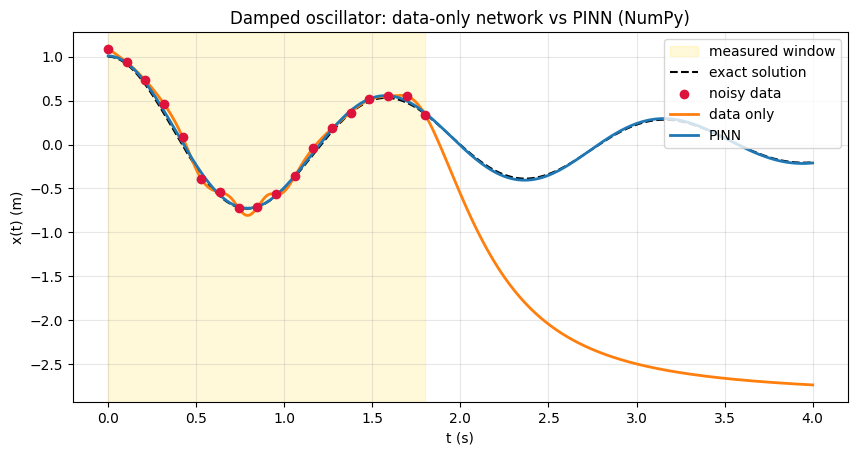

In [19]:
pred_data = forward_jets(params_data, t_grid)[0]
pred_pinn = forward_jets(params_pinn, t_grid)[0]

print(f"{'':28s}{'inside window':>15s}{'outside window':>16s}{'overall':>10s}")
print(f"{'noisy data (reference)':28s}{rmse(x_obs, true_solution(t_obs)):15.3f}{'-':>16s}{'-':>10s}")
for name, pred in (("data only", pred_data), ("PINN", pred_pinn)):
    e = window_errors(pred)
    print(f"{name:28s}{e['inside window']:15.3f}{e['outside window']:16.3f}{e['overall']:10.3f}")
print("(RMSE against the exact solution, in metres)")

plt.figure(figsize=(10, 4.8))
plt.axvspan(t_min, t_obs_end, color="gold", alpha=0.15, label="measured window")
plt.plot(t_grid, x_exact_grid, "k--", label="exact solution")
plt.scatter(t_obs, x_obs, color="crimson", zorder=3, label="noisy data")
plt.plot(t_grid, pred_data, color="tab:orange", lw=2, label="data only")
plt.plot(t_grid, pred_pinn, color="tab:blue", lw=2, label="PINN")
plt.xlabel("t (s)")
plt.ylabel("x(t) (m)")
plt.title("Damped oscillator: data-only network vs PINN (NumPy)")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()

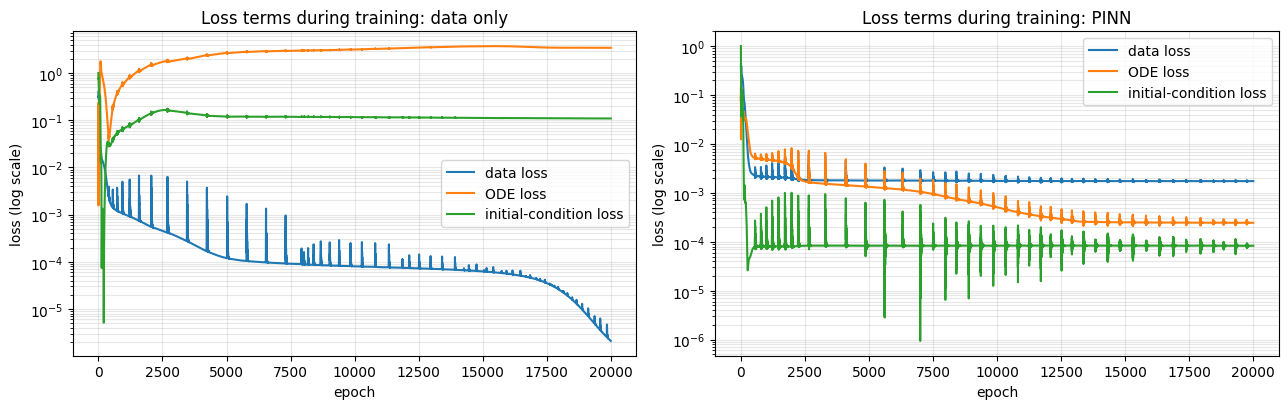

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, hist, title in ((axes[0], hist_data, "data only"), (axes[1], hist_pinn, "PINN")):
    ax.semilogy(hist[:, 1], label="data loss")
    ax.semilogy(hist[:, 2], label="ODE loss")
    ax.semilogy(hist[:, 3], label="initial-condition loss")
    ax.set_title(f"Loss terms during training: {title}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss (log scale)")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
plt.show()

**What to notice.**

* Inside the measured window both networks follow the data. The data-only network's error there is about the same as the noise itself, while the PINN's is lower, because the equation helps it ignore part of the noise.
* The data-only network pushes its data loss to almost zero, far below the noise level (the noise variance is $0.05^2=0.0025$). A loss that low means it is reproducing the noise reading by reading.
* Outside the window they part ways. The data-only network was never told anything there, and in this run its curve simply falls away to a large negative value. The PINN is held to the equation over the whole interval, so it carries on with the decaying swing and stays very close to the exact curve.
* In the loss plots, the ODE loss of the data-only network (measured, but not minimised) grows to a few units, so its curve badly breaks the equation. For the PINN the same quantity falls to about 0.0002.

## A9. Energy check
Section 4.6 showed that the energy $E=\tfrac12m\dot x^2+\tfrac12kx^2$ of a real damped oscillator can only go down. We can compute the energy of each network from its own $\hat x$ and $\hat x'$ (our forward pass already returns both) and see whether the network respects this. We also count how much of the time axis the energy goes *up*.

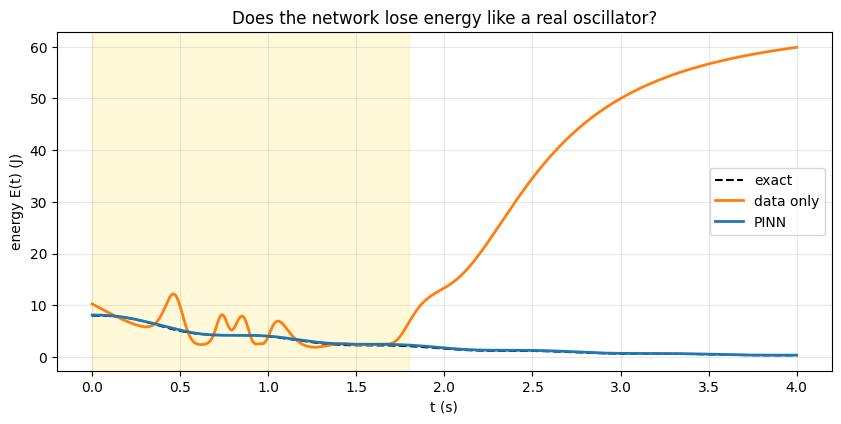

share of the time axis where energy rises:  data only = 74.2%,  PINN = 0.0%,  exact = 0.0%


In [21]:
def network_energy(params, t):
    X, X1, _, _ = forward_jets(params, t)
    return (0.5 * m * X1**2 + 0.5 * k * X**2).ravel()

E_exact = true_energy(t_grid).ravel()
E_data = network_energy(params_data, t_grid)
E_pinn = network_energy(params_pinn, t_grid)

def fraction_rising(E, tol=1e-3):
    # share of grid steps where the energy increases by more than a small tolerance
    return float(np.mean(np.diff(E) > tol * E[0]))

plt.figure(figsize=(10, 4.4))
plt.axvspan(t_min, t_obs_end, color="gold", alpha=0.15)
plt.plot(t_grid, E_exact, "k--", label="exact")
plt.plot(t_grid, E_data, color="tab:orange", lw=2, label="data only")
plt.plot(t_grid, E_pinn, color="tab:blue", lw=2, label="PINN")
plt.xlabel("t (s)")
plt.ylabel("energy E(t) (J)")
plt.title("Does the network lose energy like a real oscillator?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"share of the time axis where energy rises:  data only = {100*fraction_rising(E_data):.1f}%,  "
      f"PINN = {100*fraction_rising(E_pinn):.1f}%,  exact = {100*fraction_rising(E_exact):.1f}%")

The energy of the exact solution falls steadily (the rate changes as kinetic and spring energy trade places, but it never goes up). The PINN follows it closely. The data-only network's energy jumps around even inside the measured window, and outside it climbs to many times its starting value. A real damped oscillator cannot do that. This is the kind of check you can run on a real model without knowing the exact answer, which is what makes it useful.

## A10. The training video and GIF

Now we turn the snapshots into an animation. Both networks are shown side by side with the epoch counter above them. The strip at the bottom shows each network's error against the exact solution, on a log scale, growing as training proceeds.

`make_training_video` writes:

* **a GIF** with Pillow (always works, no extra software),
* **an MP4** with `ffmpeg` (better quality and smaller; the code looks for `ffmpeg` on your computer and falls back to the `imageio-ffmpeg` package if you have it).

If you already have the MP4 and want a GIF made from it with a clean colour palette, use `convert_mp4_to_gif`, shown after that.

In [22]:
gif_path = MEDIA_DIR / "damped_oscillator_training.gif"
mp4_path = MEDIA_DIR / "damped_oscillator_training.mp4"

anim = make_training_video(snap_epochs, snaps_data, snaps_pinn,
                           mp4_path=mp4_path, gif_path=gif_path, fps=12)

saved GIF: media/damped_oscillator_training.gif  (0.9 MB)
saved MP4: media/damped_oscillator_training.mp4  (0.7 MB)


In [23]:
# optional: build a GIF from the MP4 with ffmpeg (a palette is computed for cleaner colours)
convert_mp4_to_gif(mp4_path, MEDIA_DIR / "damped_oscillator_training_from_mp4.gif", fps=12, width=800)

converted media/damped_oscillator_training.mp4 -> media/damped_oscillator_training_from_mp4.gif  (0.9 MB)


PosixPath('media/damped_oscillator_training_from_mp4.gif')

Here is the GIF. (In Jupyter it plays inline. If you open this notebook somewhere that does not play it, open the file in the `media` folder directly.)

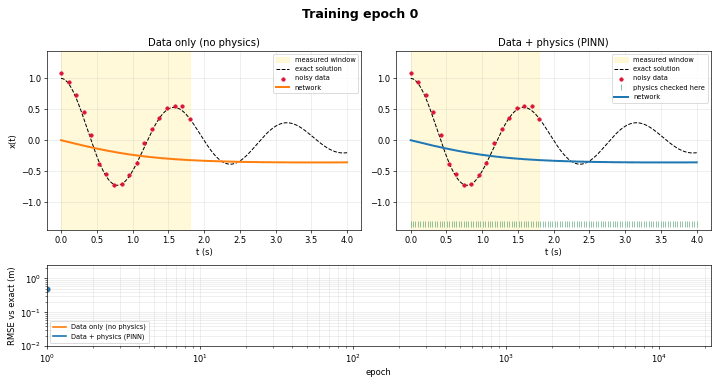

In [24]:
from IPython.display import Image, display
display(Image(filename=str(gif_path)))

A still picture of a few moments in training, for places where animations and sliders do not show (for example, a GitHub preview):

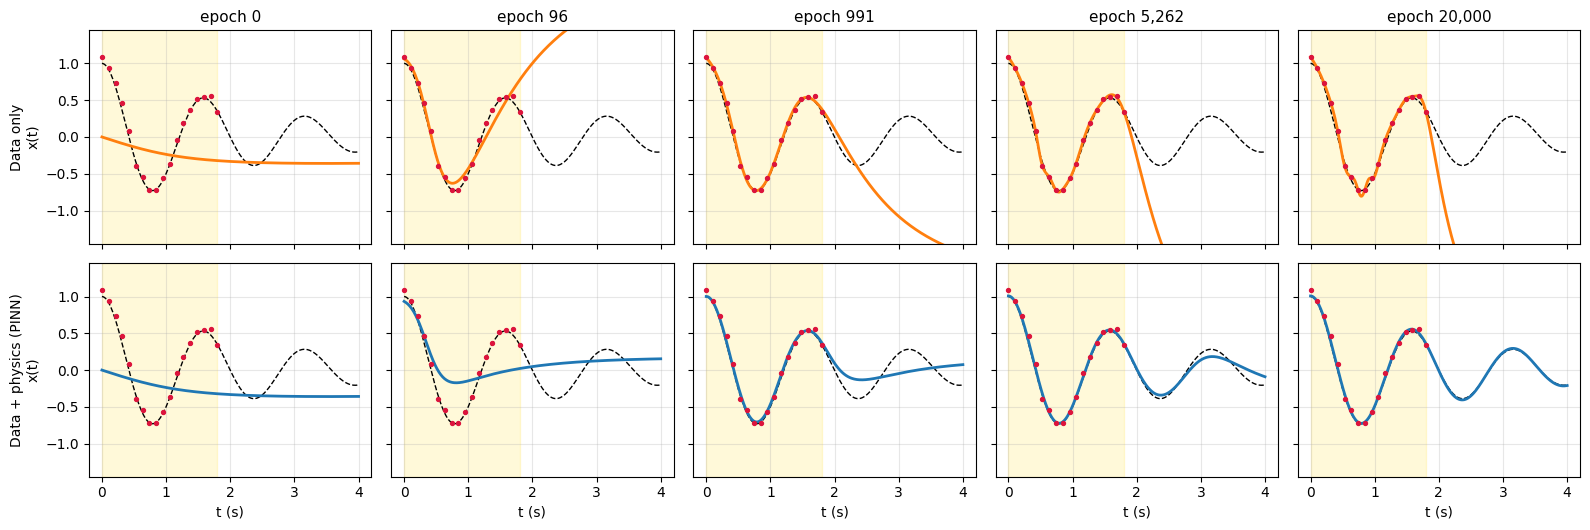

In [25]:
snapshot_grid(snap_epochs, snaps_data, snaps_pinn, picks=(0, 100, 1000, 5000, 20000))

And a slider to move through training by hand (Jupyter or Colab):

In [26]:
scrub_epochs(snap_epochs, snaps_data, snaps_pinn)

interactive(children=(SelectionSlider(description='epoch', layout=Layout(width='85%'), options=(('0', 0), ('1'…

## A11. Extension: an inverse problem in NumPy
*This section goes beyond the main experiment.*

Suppose we do not know the damping coefficient. We pretend the stiffness $k$, the mass and the starting conditions are known, make $c$ a trainable number with a deliberately wrong starting guess (0.1, when the truth is 0.8), and let training adjust it. The gradient with respect to $c$ was derived in background section 11 and checked in A4.

The data window and the noise are the same as before. We try two very different starting guesses, one far below the truth and one far above, to see whether they end up in the same place.

--- starting guess c = 0.1 ---
final estimate c = 0.771   (true value 0.8)
--- starting guess c = 2.0 ---
final estimate c = 0.775   (true value 0.8)


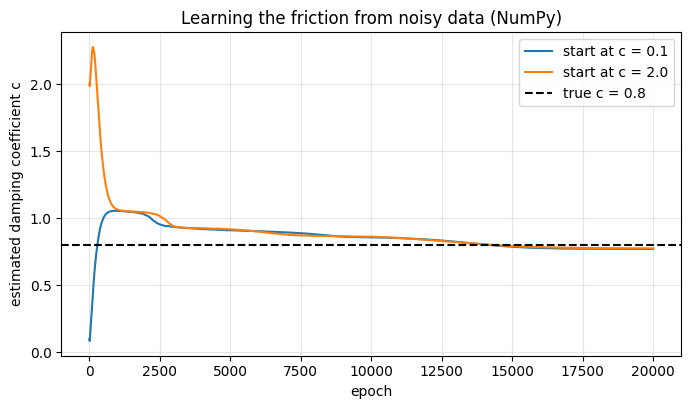

In [27]:
c_runs = {}
for c_start in (0.1, 2.0):
    print(f"--- starting guess c = {c_start} ---")
    _, _, _, c_hist = train((1.0, 1.0, 1.0), learn_c=True, c_start=c_start, verbose=False)
    c_runs[c_start] = c_hist
    print(f"final estimate c = {c_hist[-1]:.3f}   (true value {c})")

plt.figure(figsize=(8, 4.2))
for c_start, hist in c_runs.items():
    plt.plot(hist, label=f"start at c = {c_start}")
plt.axhline(c, color="k", ls="--", label=f"true c = {c}")
plt.xlabel("epoch")
plt.ylabel("estimated damping coefficient c")
plt.title("Learning the friction from noisy data (NumPy)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Both starting guesses, one far below and one far above the truth, end at nearly the same value, about 0.77. That is a good sign that the answer is set by the data and the equation and not by where we began. It is close to the true value of 0.8 but not exactly on it (a little under 4% low). We only have 18 noisy readings covering about one swing, so some error is expected. More data, a longer window or less noise would bring it closer. Treat this as a demonstration of the idea, not a precise measurement.

**End of Part A.** Everything here was built from NumPy alone: a network that returns its own first and second time derivatives, hand-derived gradients checked against finite differences, an optimiser, a training video, and an inverse problem. Part B repeats the experiment in PyTorch, where the derivative work is automatic.

---
---
# Part B: PyTorch and more advanced tools

The experiment is the same: the same constants, the same noisy readings of the first 1.8 seconds, the same physics times, the same network shape and the same training schedule. What changes is who does the calculus.

1. **Automatic differentiation** gives us $\hat x'(t)$ and $\hat x''(t)$. We call PyTorch's `autograd.grad` twice and never write the formulas from background section 8.
2. **Backpropagation** through the whole loss, including both derivatives, is a single call to `loss.backward()`. The page of algebra in A3 collapses into one line.

The first half (B1 to B8) rebuilds the experiment and the video in PyTorch. The second half (B9 to B14) uses tools that people use on bigger problems: an inverse problem with a trainable constant, the L-BFGS optimiser, the functional `torch.func` interface, a loss-weight study, an energy check, and an optional run with the DeepXDE library.

> **Setup needed.** This part needs PyTorch (`pip install torch`; Colab already has it). Run the **Setup** section first, since the constants, data and helper functions come from there.
>
> **Runtime.** Each 20,000-epoch training run takes a few minutes on a laptop CPU, because differentiating twice through the network costs more than a plain forward pass. The whole of Part B takes roughly 15 to 25 minutes on a CPU.

## B1. Imports and random seed
We fix the seed so results repeat from run to run on the same machine.

In [28]:
import copy
import torch
import torch.nn as nn

torch.manual_seed(0)

## B2. Data as tensors
The constants and measurements come from the Setup section. PyTorch works with `float32` tensors, and plain Python floats are used for the physical constants inside the loss so there are no surprises when numbers of different types are mixed.

In [29]:
# plain Python floats for use inside the loss
m_f, c_f, k_f = float(m), float(c), float(k)
x0_f, v0_f, w0_f = float(x0), float(v0), float(omega0)

# tensors (one row per time point)
t_obs_t = torch.tensor(t_obs, dtype=torch.float32)
x_obs_t = torch.tensor(x_obs, dtype=torch.float32)
t_phys_t = torch.tensor(t_phys, dtype=torch.float32)
t_grid_t = torch.tensor(t_grid, dtype=torch.float32)

print(t_obs_t.shape, t_phys_t.shape, t_grid_t.shape)

torch.Size([18, 1]) torch.Size([120, 1]) torch.Size([400, 1])


## B3. The network
A fully connected network with three hidden layers of 32 neurons and $\tanh$ activations, the same shape as in Part A. `nn.Linear(a, b)` computes $\mathbf x\mathbf W+\mathbf b$. We apply the same Xavier-uniform initialisation and zero biases that we coded by hand in A1 (the random numbers themselves differ, because PyTorch and NumPy use different generators).

In [30]:
class PINN(nn.Module):
    def __init__(self, hidden=(32, 32, 32)):
        super().__init__()
        sizes = [1, *hidden, 1]
        layers = []
        for i in range(len(sizes) - 1):
            linear = nn.Linear(sizes[i], sizes[i + 1])
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)
            layers.append(linear)
            if i < len(sizes) - 2:          # no activation after the last layer
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)

    def forward(self, t):
        # input shape (N, 1) -> output shape (N, 1)
        return self.net(t)

## B4. Differentiating with autograd
`torch.autograd.grad(y, t, ...)` returns $\partial y/\partial t$. Two details matter:

* `grad_outputs=torch.ones_like(y)`: `y` has one entry per time point, and each entry depends only on its own time. Passing ones asks for the derivative of every entry with respect to its own time.
* `create_graph=True`: PyTorch keeps a record of how the derivative was computed. We need this for two reasons. First, to take a **second** derivative, we differentiate the first one. Second, the loss contains these derivatives and we differentiate the loss with respect to the weights during training. Without `create_graph=True` both would fail.

Calling the helper twice gives the acceleration: `x_t = derivative(x, t)`, then `x_tt = derivative(x_t, t)`.

In [31]:
def derivative(y, t):
    # dy/dt for every entry of y, keeping the graph so we can differentiate again
    return torch.autograd.grad(y, t, grad_outputs=torch.ones_like(y), create_graph=True)[0]

## B5. The loss terms
These are the four terms of background section 7. `ode_loss` switches on gradient tracking for the time tensor, gets $\hat x'$ and $\hat x''$ with two calls to `derivative`, and forms the scaled residual $(m\hat x''+c\hat x'+k\hat x)/k$. The damping coefficient is an argument (`c_val`), so in B9 we can pass in a trainable value.

In [32]:
def data_loss(model, t, x):
    return torch.mean((model(t) - x) ** 2)


def ode_loss(model, t, c_val):
    t = t.clone().requires_grad_(True)
    x = model(t)
    x_t = derivative(x, t)           # velocity
    x_tt = derivative(x_t, t)        # acceleration
    residual = (m_f * x_tt + c_val * x_t + k_f * x) / k_f
    return torch.mean(residual ** 2)


def ic_loss(model):
    t0 = torch.zeros(1, 1, requires_grad=True)
    x = model(t0)
    x_t = derivative(x, t0)
    return torch.mean((x - x0_f) ** 2) + torch.mean(((x_t - v0_f) / w0_f) ** 2)

## B6. A training function
One function trains either model, as in Part A: `lam=(1, 0, 0)` for data only and `lam=(1, 1, 1)` for the PINN. The learning rate shrinks geometrically from $3\times10^{-3}$ to $10^{-4}$ using PyTorch's `ExponentialLR`, whose per-epoch factor is $\gamma=(\eta_1/\eta_0)^{1/K}$. It reproduces the formula of background section 9. Snapshots of the prediction are saved at the chosen epochs for the video. With `learn_c=True` the damping coefficient becomes a trainable parameter.

When $\lambda_{\text{ODE}}=0$ the function skips the physics terms entirely (they would not change anything), so the logged ODE and IC losses for the data-only model are zero because they were never evaluated. In Part A we measured them anyway.

In [33]:
EPOCHS = 20000
LR_START, LR_END = 3e-3, 1e-4


def train_torch(lam, epochs=EPOCHS, seed=0, t_ode=None, learn_c=False, c_start=0.1,
                snapshot_epochs=None, verbose=True, print_every=2000):
    t_ode = t_phys_t if t_ode is None else t_ode
    torch.manual_seed(seed)
    model = PINN()
    params = list(model.parameters())
    c_param = None
    if learn_c:
        c_param = nn.Parameter(torch.tensor(float(c_start)))     # the unknown damping coefficient
        params.append(c_param)

    optimizer = torch.optim.Adam(params, lr=LR_START)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer, gamma=(LR_END / LR_START) ** (1.0 / epochs))
    snap_set = set(snapshot_epochs) if snapshot_epochs is not None else set()

    history, snapshots, c_history = [], [], []
    for epoch in range(epochs + 1):
        if epoch in snap_set:
            with torch.no_grad():
                snapshots.append(model(t_grid_t).numpy().ravel().copy())
        if epoch == epochs:
            break

        optimizer.zero_grad()
        c_val = c_param if learn_c else c_f
        l_data = data_loss(model, t_obs_t, x_obs_t)
        l_ode = ode_loss(model, t_ode, c_val) if lam[1] > 0 else torch.zeros(())
        l_ic = ic_loss(model) if lam[2] > 0 else torch.zeros(())
        total = lam[0] * l_data + lam[1] * l_ode + lam[2] * l_ic

        total.backward()
        optimizer.step()
        scheduler.step()

        history.append([total.item(), l_data.item(), l_ode.item(), l_ic.item()])
        if learn_c:
            c_history.append(c_param.item())
        if verbose and (epoch + 1) % print_every == 0:
            extra = f", c = {c_param.item():.3f}" if learn_c else ""
            print(f"epoch {epoch+1:6d}/{epochs}  total = {total.item():.6f}  data = {l_data.item():.6f}  "
                  f"ODE = {l_ode.item():.6f}  IC = {l_ic.item():.6f}{extra}")
    return model, np.array(history), np.array(snapshots), np.array(c_history)


def predict(model, t_np):
    with torch.no_grad():
        return model(torch.tensor(t_np, dtype=torch.float32)).numpy()

## B7. Train the two networks and compare
Same recipe as A7. Both start from the same seed, so they begin with identical weights.

In [34]:
snap_epochs = make_snapshot_epochs(EPOCHS)

print("=== data only ===")
model_data, hist_data_t, snaps_data_t, _ = train_torch((1.0, 0.0, 0.0), snapshot_epochs=snap_epochs)

print("\n=== PINN ===")
model_pinn, hist_pinn_t, snaps_pinn_t, _ = train_torch((1.0, 1.0, 1.0), snapshot_epochs=snap_epochs)

=== data only ===
epoch   2000/20000  total = 0.000445  data = 0.000445  ODE = 0.000000  IC = 0.000000
epoch   4000/20000  total = 0.000009  data = 0.000009  ODE = 0.000000  IC = 0.000000
epoch   6000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000
epoch   8000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000
epoch  10000/20000  total = 0.000001  data = 0.000001  ODE = 0.000000  IC = 0.000000
epoch  12000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000
epoch  14000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000
epoch  16000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000
epoch  18000/20000  total = 0.000001  data = 0.000001  ODE = 0.000000  IC = 0.000000
epoch  20000/20000  total = 0.000000  data = 0.000000  ODE = 0.000000  IC = 0.000000

=== PINN ===
epoch   2000/20000  total = 0.002537  data = 0.001773  ODE = 0.000679  IC = 0.000085
epoch   4000/20000  total = 0.002

                              inside window  outside window   overall
noisy data (reference)                0.053               -         -
data only                             0.052           1.162     0.862
PINN                                  0.021           0.011     0.016
(RMSE against the exact solution, in metres)


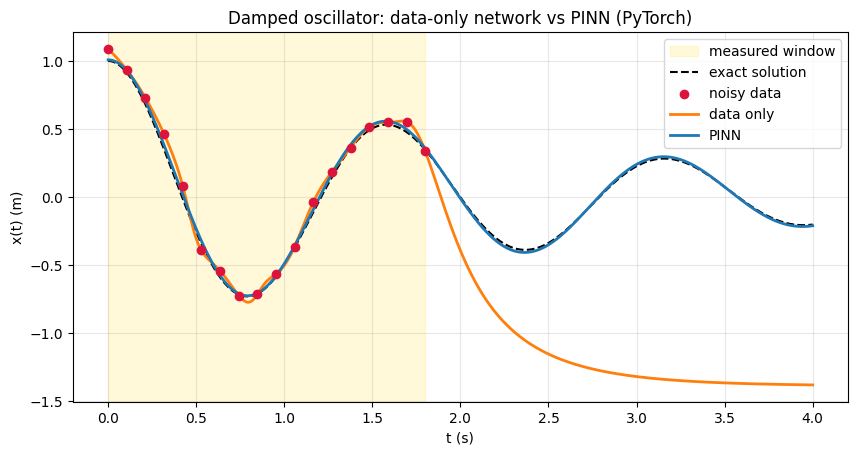

In [35]:
pred_data_t = predict(model_data, t_grid)
pred_pinn_t = predict(model_pinn, t_grid)

print(f"{'':28s}{'inside window':>15s}{'outside window':>16s}{'overall':>10s}")
print(f"{'noisy data (reference)':28s}{rmse(x_obs, true_solution(t_obs)):15.3f}{'-':>16s}{'-':>10s}")
for name, pred in (("data only", pred_data_t), ("PINN", pred_pinn_t)):
    e = window_errors(pred)
    print(f"{name:28s}{e['inside window']:15.3f}{e['outside window']:16.3f}{e['overall']:10.3f}")
print("(RMSE against the exact solution, in metres)")

plt.figure(figsize=(10, 4.8))
plt.axvspan(t_min, t_obs_end, color="gold", alpha=0.15, label="measured window")
plt.plot(t_grid, x_exact_grid, "k--", label="exact solution")
plt.scatter(t_obs, x_obs, color="crimson", zorder=3, label="noisy data")
plt.plot(t_grid, pred_data_t, color="tab:orange", lw=2, label="data only")
plt.plot(t_grid, pred_pinn_t, color="tab:blue", lw=2, label="PINN")
plt.xlabel("t (s)")
plt.ylabel("x(t) (m)")
plt.title("Damped oscillator: data-only network vs PINN (PyTorch)")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.show()

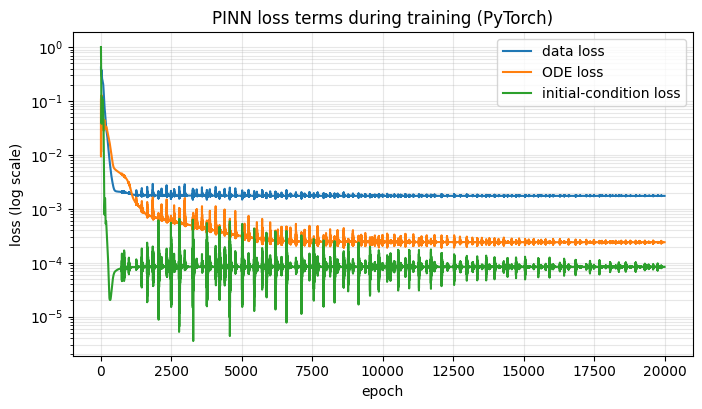

In [36]:
plt.figure(figsize=(8, 4.2))
plt.semilogy(hist_pinn_t[:, 1], label="data loss")
plt.semilogy(hist_pinn_t[:, 2], label="ODE loss")
plt.semilogy(hist_pinn_t[:, 3], label="initial-condition loss")
plt.xlabel("epoch")
plt.ylabel("loss (log scale)")
plt.title("PINN loss terms during training (PyTorch)")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

The pattern should match Part A: both networks follow the data inside the measured window, and only the PINN keeps the decaying swing going outside it. The exact numbers will differ a little from Part A, because the starting weights differ and PyTorch works in 32-bit numbers where our NumPy code used 64-bit ones.

## B8. The training video, again, from the PyTorch run
The same helper makes the animation. The files get a `_pytorch` suffix so they do not overwrite the NumPy ones. After that: a still picture of a few moments, and the epoch slider.

saved GIF: media/damped_oscillator_training_pytorch.gif  (0.9 MB)
saved MP4: media/damped_oscillator_training_pytorch.mp4  (0.7 MB)


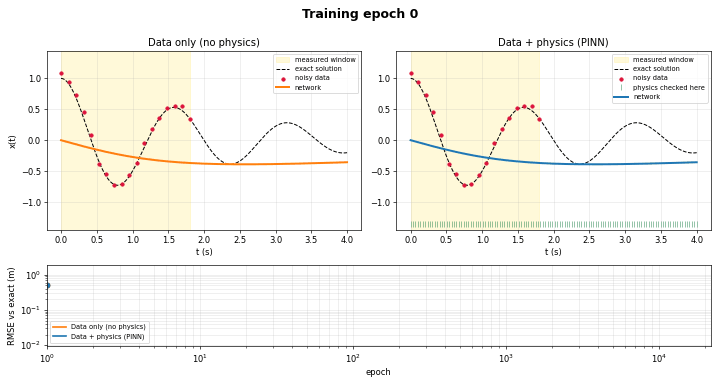

In [37]:
gif_path_t = MEDIA_DIR / "damped_oscillator_training_pytorch.gif"
mp4_path_t = MEDIA_DIR / "damped_oscillator_training_pytorch.mp4"

anim_t = make_training_video(snap_epochs, snaps_data_t, snaps_pinn_t,
                             mp4_path=mp4_path_t, gif_path=gif_path_t, fps=12)

from IPython.display import Image, display
display(Image(filename=str(gif_path_t)))

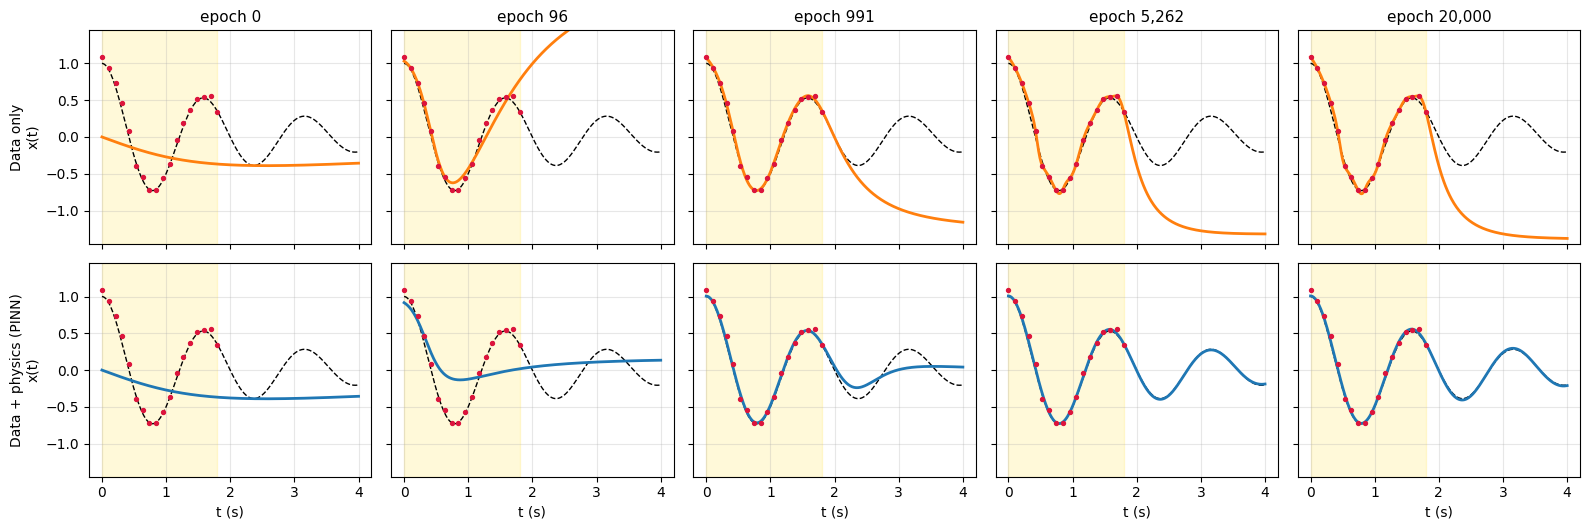

In [38]:
snapshot_grid(snap_epochs, snaps_data_t, snaps_pinn_t, picks=(0, 100, 1000, 5000, 20000))

In [39]:
scrub_epochs(snap_epochs, snaps_data_t, snaps_pinn_t)

interactive(children=(SelectionSlider(description='epoch', layout=Layout(width='85%'), options=(('0', 0), ('1'…

---
## Advanced additions

Everything below goes beyond the basic experiment.

## B9. Inverse problem: learn the damping coefficient
Now $c$ is unknown. We make it an `nn.Parameter`, hand it to the optimiser together with the network weights, and pass it into the ODE loss. PyTorch works out $\partial\mathcal L/\partial c$ on its own. In A11 we derived and coded that gradient by hand, and it is the same quantity.

As in A11 we start from two very different guesses, 0.1 and 2.0, and watch where they end up.

--- starting guess c = 0.1 ---
final estimate c = 0.770   (true value 0.8)
--- starting guess c = 2.0 ---
final estimate c = 0.769   (true value 0.8)


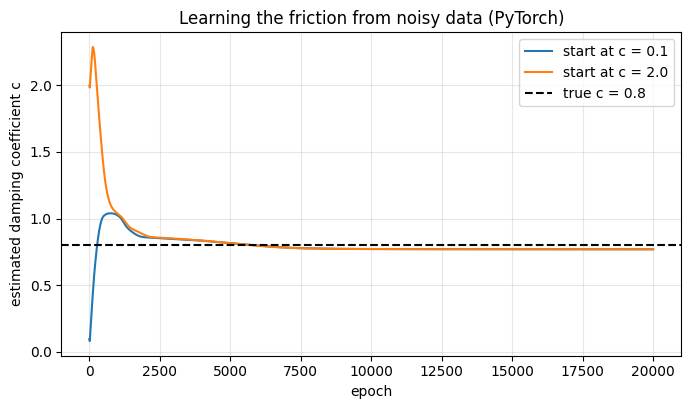

In [40]:
c_runs_t = {}
for c_start in (0.1, 2.0):
    print(f"--- starting guess c = {c_start} ---")
    _, _, _, c_hist_t = train_torch((1.0, 1.0, 1.0), learn_c=True, c_start=c_start, verbose=False)
    c_runs_t[c_start] = c_hist_t
    print(f"final estimate c = {c_hist_t[-1]:.3f}   (true value {c})")

plt.figure(figsize=(8, 4.2))
for c_start, hist in c_runs_t.items():
    plt.plot(hist, label=f"start at c = {c_start}")
plt.axhline(c, color="k", ls="--", label=f"true c = {c}")
plt.xlabel("epoch")
plt.ylabel("estimated damping coefficient c")
plt.title("Learning the friction from noisy data (PyTorch)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Compare with the NumPy result in A11. If the two agree on roughly where the estimate settles, that is a useful cross-check between two independent implementations. Small differences are expected for the same reasons as before.

## B10. Polishing with L-BFGS
Adam is steady but it only uses the slope of the loss. **L-BFGS** is a quasi-Newton method: from the last several gradients it builds a rough picture of how the loss curves, and takes larger, better-aimed steps (Liu and Nocedal, 1989). A common PINN recipe is Adam first for the rough shape, then L-BFGS to polish.

PyTorch's L-BFGS needs a **closure**, a function that recomputes the loss and its gradients on demand, because the optimiser may evaluate the loss several times in one step. It works best in 64-bit arithmetic, and our model is 32-bit, so progress can stall or occasionally produce non-finite values. The cell checks for that and keeps the original model if it happens.

In [41]:
model_lbfgs = copy.deepcopy(model_pinn)
lbfgs = torch.optim.LBFGS(model_lbfgs.parameters(), lr=1.0, max_iter=500, history_size=50,
                          tolerance_grad=1e-10, tolerance_change=1e-14,
                          line_search_fn="strong_wolfe")

def closure():
    lbfgs.zero_grad()
    loss = (data_loss(model_lbfgs, t_obs_t, x_obs_t)
            + ode_loss(model_lbfgs, t_phys_t, c_f)
            + ic_loss(model_lbfgs))
    loss.backward()
    return loss

before = window_errors(predict(model_pinn, t_grid))
lbfgs.step(closure)
after_pred = predict(model_lbfgs, t_grid)

if np.isfinite(after_pred).all():
    after = window_errors(after_pred)
    print(f"overall RMSE before L-BFGS: {before['overall']:.4f} m")
    print(f"overall RMSE after  L-BFGS: {after['overall']:.4f} m")
else:
    print("L-BFGS produced non-finite values in 32-bit arithmetic; keeping the Adam result.")
    model_lbfgs = model_pinn

overall RMSE before L-BFGS: 0.0162 m
overall RMSE after  L-BFGS: 0.0162 m


With only 18 noisy readings, the limit on accuracy is the noise in the data, so do not expect a dramatic improvement in RMSE. What L-BFGS does improve is how completely the loss is minimised. The gain is larger when the data are clean, or when the problem is the equation alone.

## B11. Second derivatives with `torch.func`
In B4 we called `autograd.grad` twice. PyTorch also has a functional interface, `torch.func`, where you write a function for a **single** time point and then ask for its derivative:

* `jacrev(f)` is a new function that returns $f'$,
* `jacrev(jacrev(f))` returns $f''$,
* `vmap(g)` applies `g` to every point of a batch at once.

This style is common in more advanced PINN code because it extends naturally to several inputs, mixed derivatives and PDEs. Below we compute $\hat x'$ and $\hat x''$ both ways on the trained PINN and compare.

In [42]:
from torch.func import vmap, jacrev

def x_scalar(t_scalar):
    # network output for one time point (scalar in, scalar out)
    return model_pinn(t_scalar.reshape(1, 1)).reshape(())

first_derivative = vmap(jacrev(x_scalar))
second_derivative = vmap(jacrev(jacrev(x_scalar)))

t_check = torch.linspace(0.0, 4.0, 9)
x_t_func = first_derivative(t_check)
x_tt_func = second_derivative(t_check)

# the same derivatives with autograd.grad
t_ag = t_check.clone().reshape(-1, 1).requires_grad_(True)
x_ag = model_pinn(t_ag)
x_t_ag = derivative(x_ag, t_ag)
x_tt_ag = derivative(x_t_ag, t_ag)

print("largest difference in x':", float((x_t_func - x_t_ag.reshape(-1)).abs().max()))
print("largest difference in x'':", float((x_tt_func - x_tt_ag.reshape(-1)).abs().max()))

largest difference in x': 2.980232238769531e-07
largest difference in x'': 7.450580596923828e-07


/tmp/ipykernel_4856/2003172501.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("largest difference in x':", float((x_t_func - x_t_ag.reshape(-1)).abs().max()))


The two interfaces agree up to floating-point rounding.

## B12. How much should we trust the physics? A loss-weight study
$\lambda_{\text{ODE}}$ decides who wins when data and equation disagree. We keep $\lambda_{\text{data}}=\lambda_{\text{IC}}=1$ and vary the ODE weight over several orders of magnitude. To keep the runtime reasonable, each run is 6,000 epochs (the learning-rate schedule is shortened to match), so the numbers are not directly comparable with the 20,000-epoch runs above.

Here the equation is **exactly right**, so we expect a larger weight to help, especially outside the measured window. In a real problem where the equation is only approximate, you would want the data to keep a say, and this plot is a way to find a sensible balance.

lambda_ODE =   0.00   RMSE outside window = 0.549 m   overall = 0.408 m
lambda_ODE =   0.01   RMSE outside window = 0.181 m   overall = 0.137 m
lambda_ODE =   0.10   RMSE outside window = 0.170 m   overall = 0.128 m
lambda_ODE =   1.00   RMSE outside window = 0.017 m   overall = 0.018 m
lambda_ODE =  10.00   RMSE outside window = 0.080 m   overall = 0.060 m


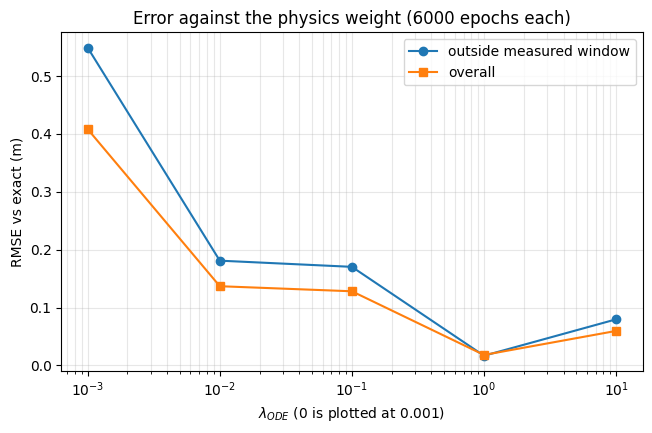

In [43]:
lam_values = [0.0, 0.01, 0.1, 1.0, 10.0]
sweep_outside, sweep_overall = [], []
for lam_ode in lam_values:
    model_s, _, _, _ = train_torch((1.0, lam_ode, 1.0), epochs=6000, verbose=False)
    e = window_errors(predict(model_s, t_grid))
    sweep_outside.append(e["outside window"])
    sweep_overall.append(e["overall"])
    print(f"lambda_ODE = {lam_ode:6.2f}   RMSE outside window = {e['outside window']:.3f} m   overall = {e['overall']:.3f} m")

plt.figure(figsize=(7.5, 4.4))
xs = [max(v, 1e-3) for v in lam_values]
plt.semilogx(xs, sweep_outside, "o-", label="outside measured window")
plt.semilogx(xs, sweep_overall, "s-", label="overall")
plt.xlabel(r"$\lambda_{ODE}$ (0 is plotted at 0.001)")
plt.ylabel("RMSE vs exact (m)")
plt.title("Error against the physics weight (6000 epochs each)")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()

## B13. Energy check with autograd
The same energy test as in A9, now using autograd for $\hat x'$. We compare the exact energy, the data-only network and the PINN.

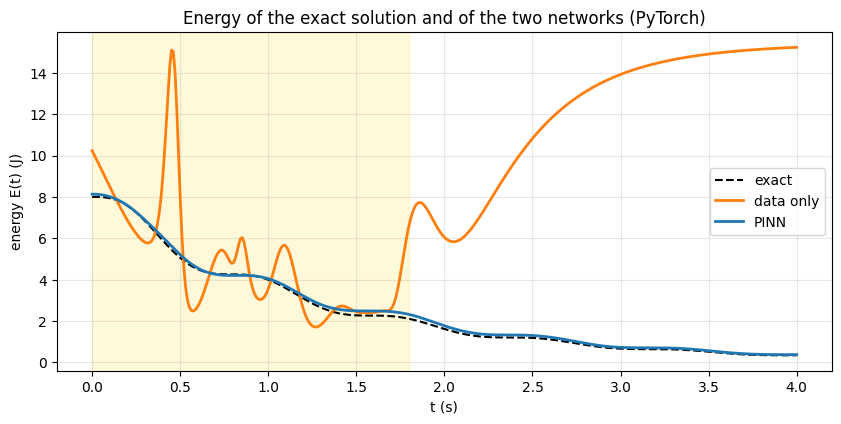

In [44]:
def torch_energy(model, t_np):
    t = torch.tensor(t_np, dtype=torch.float32, requires_grad=True)
    x = model(t)
    x_t = derivative(x, t)
    return (0.5 * m_f * x_t**2 + 0.5 * k_f * x**2).detach().numpy().ravel()

plt.figure(figsize=(10, 4.4))
plt.axvspan(t_min, t_obs_end, color="gold", alpha=0.15)
plt.plot(t_grid, true_energy(t_grid), "k--", label="exact")
plt.plot(t_grid, torch_energy(model_data, t_grid), color="tab:orange", lw=2, label="data only")
plt.plot(t_grid, torch_energy(model_pinn, t_grid), color="tab:blue", lw=2, label="PINN")
plt.xlabel("t (s)")
plt.ylabel("energy E(t) (J)")
plt.title("Energy of the exact solution and of the two networks (PyTorch)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## B14. Optional: the same problem with DeepXDE
DeepXDE (Lu et al., 2021) is a library built for PINNs. You describe the equation, the conditions and the data, and it takes care of the network, the choice of points and the training loop. It is the quickest route once you know what is happening inside, which is why Parts A and B came first.

This cell is optional. It runs only if DeepXDE is installed (`pip install deepxde`), and we ask it to use the PyTorch backend. Here the residual uses the second derivative (`dde.grad.hessian`), the first derivative (`dde.grad.jacobian`), one initial condition on $x(0)$, a second initial condition on $\dot x(0)$ through an operator condition, and the noisy readings as extra data constraints.

*Library interfaces change between versions. If this cell fails, check the DeepXDE documentation for your version. Nothing else in the notebook depends on it.*

In [45]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 10.5 MB/s eta 0:00:00


In [46]:
try:
    os.environ.setdefault("DDE_BACKEND", "pytorch")
    import deepxde as dde

    def ode_system(t, x):
        x_t = dde.grad.jacobian(x, t)
        x_tt = dde.grad.hessian(x, t)
        return (m_f * x_tt + c_f * x_t + k_f * x) / k_f

    def at_start(t, on_initial):
        return on_initial                       # for the position condition (t = 0 only)

    def at_start_boundary(t, on_boundary):
        return on_boundary and np.isclose(t[0], t_min)     # for the velocity condition (t = 0 only)

    geom = dde.geometry.TimeDomain(t_min, t_max)
    ic_position = dde.icbc.IC(geom, lambda t: x0_f, at_start)
    ic_velocity = dde.icbc.OperatorBC(
        geom, lambda inputs, outputs, X: dde.grad.jacobian(outputs, inputs, i=0, j=0) - v0_f,
        at_start_boundary)
    observations = dde.icbc.PointSetBC(t_obs, x_obs)

    data = dde.data.PDE(geom, ode_system, [ic_position, ic_velocity, observations],
                        num_domain=N_phys, num_boundary=2)
    net = dde.nn.FNN([1, 32, 32, 32, 1], "tanh", "Glorot uniform")
    dde_model = dde.Model(data, net)
    dde_model.compile("adam", lr=3e-3)
    dde_model.train(iterations=20000, display_every=5000)

    x_dde = dde_model.predict(t_grid)
    e = window_errors(x_dde)
    print(f"DeepXDE RMSE: inside {e['inside window']:.3f}, outside {e['outside window']:.3f}, overall {e['overall']:.3f}")
except ImportError:
    print("DeepXDE is not installed, skipping this optional cell.")
except Exception as error:
    print("DeepXDE ran into a problem (often a version difference):", error)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Compiling model...
'compile' took 0.000292 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [1.95e-01, 1.00e+00, 1.50e-01, 4.66e-01]    [1.95e-01, 1.00e+00, 1.50e-01, 4.66e-01]    []  
5000      [6.83e-04, 6.86e-05, 1.26e-06, 1.80e-03]    [6.83e-04, 6.86e-05, 1.26e-06, 1.80e-03]    []  
10000     [2.52e-04, 4.69e-05, 3.64e-06, 1.84e-03]    [2.52e-04, 4.69e-05, 3.64e-06, 1.84e-03]    []  
15000     [2.69e-04, 7.29e-05, 1.54e-06, 1.75e-03]    [2.69e-04, 7.29e-05, 1.54e-06, 1.75e-03]    []  
20000     [2.31e-04, 4.75e-05, 2.24e-05, 1.82e-03]    [2.31e-04, 4.75e-05, 2.24e-05, 1.82e-03]    []  

Best model at step 15000:
  train loss: 2.09e-03
  test loss: 2.09e-03
  test metric: []

'train' took 104.578207 s

DeepXDE RMSE: inside 0.019, outside 0.012, overall 0.015


---
# Summary

| | Part A (NumPy) | Part B (PyTorch) |
|---|---|---|
| First and second time derivative of the network | Chain rule written out by hand, carried layer by layer | `torch.autograd.grad` twice, or `torch.func` |
| Gradient of the loss | Derived by hand, checked against finite differences | `loss.backward()` |
| Optimiser | Adam written from its equations, with a decaying step size | `torch.optim.Adam` with `ExponentialLR`, then `LBFGS` |
| Unknown damping coefficient | Gradient derived and coded by hand | `nn.Parameter` and autograd |
| Good for | Understanding every step | Faster experimenting, other optimisers, larger models |

**What the experiments showed**

* A network trained on the data alone matches the readings, but outside the measured window it has no reason to continue the decaying swing.
* Adding the equation and both initial conditions to the loss lets the network continue the oscillation with shrinking amplitude beyond the data. The physics is what makes the extrapolation possible.
* Checking the equation at many more times than we have measurements is free, and it is what holds the curve together in between and beyond the readings.
* The energy of a real damped oscillator can only fall. Checking the energy of a model is a test that needs no exact answer.
* The same machinery can find an unknown constant, here the friction, from noisy data.

**Limits of this example**

* The equation is linear with an exact solution, so we could measure the error directly. In real problems you usually cannot, and checks like the residual and the energy become more important.
* A single noise draw and a single random start were used. A proper study would repeat the runs over many seeds and report averages and spreads.
* The oscillation is only a couple of swings long. With many swings (a longer time span or a lighter damping), plain PINN training tends to struggle, and extra techniques such as training in time segments, better loss weighting or special input encodings are used (see the references).
* For an ODE this simple, a classical integrator such as Runge-Kutta is faster and more accurate. A PINN earns its place when data and physics must be combined, when constants are unknown, or when the problem is a PDE.

**Design choices that are ours, not part of the physics**

| Choice | Why |
|---|---|
| Residual divided by $k$; velocity error divided by $\omega_0$ | Puts all loss terms on the scale of a position so the weights can stay near 1 |
| Data only in the first 1.8 s, physics over 4 s | Makes the extrapolation test visible |
| 120 physics points | Dense enough to hold the curve over about 2.5 swings |
| Learning rate from $3\times10^{-3}$ to $10^{-4}$ | A fixed rate jitters late in training |
| 20,000 epochs | Needed for the oscillation to form |

**Things to try**

* Change `c` in S2 to make the oscillator critically damped or overdamped (the exact solution function already handles it) and see whether the PINN still works.
* Make the data window longer or shorter (`t_obs_end` in S5) and watch the data-only network and the PINN respond.
* Increase `noise_level`, or reduce the number of readings.
* Feed the ODE loss a slightly wrong damping coefficient and see how far the PINN drifts from the truth (this is what an imperfect model does).
* Lower the damping so the weight swings five or more times in the interval, and see where training starts to struggle.

# References

1. M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, Journal of Computational Physics, 378, 686–707 (2019).
2. L. Lu, X. Meng, Z. Mao, G. E. Karniadakis, *DeepXDE: A deep learning library for solving differential equations*, SIAM Review, 63(1), 208–228 (2021).
3. D. P. Kingma, J. Ba, *Adam: A method for stochastic optimization*, International Conference on Learning Representations (2015).
4. X. Glorot, Y. Bengio, *Understanding the difficulty of training deep feedforward neural networks*, Proceedings of AISTATS, 249–256 (2010).
5. D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Mathematical Programming, 45, 503–528 (1989).
6. A. G. Baydin, B. A. Pearlmutter, A. A. Radul, J. M. Siskind, *Automatic differentiation in machine learning: a survey*, Journal of Machine Learning Research, 18(153), 1–43 (2018).
7. S. Wang, Y. Teng, P. Perdikaris, *Understanding and mitigating gradient flow pathologies in physics-informed neural networks*, SIAM Journal on Scientific Computing, 43(5), A3055–A3081 (2021).
8. A. Krishnapriyan, A. Gholami, S. Zhe, R. Kirby, M. W. Mahoney, *Characterizing possible failure modes in physics-informed neural networks*, Advances in Neural Information Processing Systems 34 (2021).
9. S. Wang, X. Yu, P. Perdikaris, *When and why PINNs fail to train: A neural tangent kernel perspective*, Journal of Computational Physics, 449, 110768 (2022).
10. G. Cybenko, *Approximation by superpositions of a sigmoidal function*, Mathematics of Control, Signals and Systems, 2, 303–314 (1989).
11. W. E. Boyce, R. C. DiPrima, *Elementary Differential Equations and Boundary Value Problems*, Wiley (10th edition, 2012). Damped free vibrations and the characteristic equation.
12. J. R. Taylor, *Classical Mechanics*, University Science Books (2005). Chapter 5, damped oscillations.
13. S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd edition, Westview Press (2015).